#  Extension de l'architecture (mlp with multiple hidden layers)

## Import libraries

In [1]:
import os, time, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

from charte_graphique import appliquer_charte, BLEU, ROUGE, BLANC, GRIS, teintes
appliquer_charte()
warnings.filterwarnings("ignore")

GRIS_LIGNE = "#8A8A8A"      

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
torch.set_num_threads(1)      
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "| torch", torch.__version__)

Device : cpu | torch 2.15.0+cpu


## Load data & DataLoaders

In [2]:
DATA_DIR = os.environ.get("HAR_DIR", "../data/processed_har_data")

train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")    

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_train_s = train_df[feature_cols].to_numpy(dtype=np.float32)
y_train   = train_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
X_val_s   = val_df[feature_cols].to_numpy(dtype=np.float32)
y_val     = val_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
in_dim = X_train_s.shape[1]

print("X_train_s :", X_train_s.shape, "| X_val_s :", X_val_s.shape, "| classes :", n_classes)

def make_loader(X, y, batch_size=128, shuffle=False, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)

val_loader = make_loader(X_val_s, y_val, 512)

X_train_s : (5657, 561) | X_val_s : (1695, 561) | classes : 6


In [3]:
# Ref : régression logistique 
logreg = LogisticRegression(max_iter=500).fit(X_train_s, y_train)
pred_lr = logreg.predict(X_val_s)
ref_acc = accuracy_score(y_val, pred_lr)
ref_f1  = f1_score(y_val, pred_lr, average="macro")
print(f"Régression logistique (validation) : accuracy = {ref_acc:.4f} | F1 macro = {ref_f1:.4f}")

Régression logistique (validation) : accuracy = 0.9168 | F1 macro = 0.9187


## MLP à nombre de couches et d'activations variables


In [4]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP(nn.Module):
    
    def __init__(self, in_dim, hidden=(64,), n_classes=6, act="relu"):
        super().__init__()
        acts = [act] * len(hidden) if isinstance(act, str) else list(act)
        assert len(acts) == len(hidden), "vérfie qu'on a bien une activation par couche cachée"
        layers, d = [], in_dim
        for h, a in zip(hidden, acts):
            layers += [nn.Linear(d, h), ACTIVATIONS[a]()]
            d = h
        self.features = nn.Sequential(*layers)    #hidden part of the mlp : on enchaine tous ces couches en ordre 
        self.out_layer = nn.Linear(d, n_classes)  #d=64 taille de sortie de la derniere hidden layer

    def forward(self, x):
        return self.out_layer(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# nombre de paramètres selon l'architecture
for h in [(64,), (128,), (64, 64), (64, 64, 64)]:
    print(f"hidden = {str(h):<16} -> {count_params(MLP(in_dim, h, n_classes)):>7} paramètres")

hidden = (64,)            ->   36358 paramètres
hidden = (128,)           ->   72710 paramètres
hidden = (64, 64)         ->   40518 paramètres
hidden = (64, 64, 64)     ->   44678 paramètres


## fcts d'entraînement et d'évaluation

In [5]:
#intialize optimizerrs
def make_optimizer(name, params, lr):
    if name == "sgd":  return torch.optim.SGD(params, lr=lr)
    if name == "sgdm": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adam": return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)
#Une époque d'entraînement : loss / accuracy / F1 macro moyennés sur l'époque.
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

@torch.no_grad()
def evaluate(model, loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p),
            "f1": f1_score(y, p, average="macro"), "pred": p}

In [6]:
EPOCHS   = 150     
PATIENCE = 10      
#train avec early stopping sur la loss de validation -> restaure les meilleurs poids
def fit(model, optimizer, train_loader, epochs=EPOCHS, patience=PATIENCE):
    criterion = nn.CrossEntropyLoss()
    hist = []
    best_loss, best_state, best_ep, attente = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        tr = train_epoch(model, train_loader, criterion, optimizer)
        va = evaluate(model, val_loader)
        hist.append({"epoch": ep,
                     "train_loss": tr["loss"], "train_acc": tr["acc"], "train_f1": tr["f1"],
                     "val_loss": va["loss"],   "val_acc": va["acc"],   "val_f1": va["f1"]})
        if va["loss"] < best_loss:
            best_loss, best_ep, attente = va["loss"], ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
        if attente >= patience:
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(hist), best_ep

def run(hidden, act, opt="adam", lr=1e-3, seed=0):
    set_seed(seed)
    model = MLP(in_dim, hidden, n_classes, act).to(device)
    optimizer = make_optimizer(opt, model.parameters(), lr)
    train_loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=seed)
    t0 = time.time()
    hist, best_ep = fit(model, optimizer, train_loader)
    return {"model": model, "hist": hist, "best_epoch": best_ep, "time": time.time() - t0,
            "n_params": count_params(model)}

In [7]:
SEEDS = [0, 1, 2, 3, 4]
#  répète une configuration sur plusieurs graines """
def run_seeds(nom, hidden, act, opt="adam", lr=1e-3, seeds=SEEDS):
    runs = []
    for s in seeds:
        r = run(hidden, act, opt, lr, seed=s)
        b = r["hist"].iloc[r["best_epoch"] - 1]
        runs.append({"val_f1": b["val_f1"], "val_acc": b["val_acc"], "train_f1": b["train_f1"],
                     "best_epoch": r["best_epoch"], "time": r["time"]})
    d = pd.DataFrame(runs)
    return {"configuration": nom, "profondeur": len(hidden), "largeur": hidden[0], "params": r["n_params"],
            "val_f1": d["val_f1"].mean(), "val_f1_std": d["val_f1"].std(),
            "val_acc": d["val_acc"].mean(), "val_acc_std": d["val_acc"].std(),
            "train_f1": d["train_f1"].mean(), "train_f1_std": d["train_f1"].std(),
            "ecart": (d["train_f1"] - d["val_f1"]).mean(),
            "best_epoch": d["best_epoch"].mean(), "temps_s": d["time"].mean()}

def afficher(tab):
    """Tableau lisible : moyennes ± écarts-types arrondis."""
    out = pd.DataFrame({"configuration": tab["configuration"], "paramètres": tab["params"],
        "val F1": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tab["val_f1"], tab["val_f1_std"])],
        "val acc": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tab["val_acc"], tab["val_acc_std"])],
        "train F1": tab["train_f1"].round(4), "écart F1 (train - val)": tab["ecart"].round(4),
        "meilleure époque": tab["best_epoch"].round(1), "temps (s)": tab["temps_s"].round(1)})
    display(out.reset_index(drop=True))

## Largeur de la couche cachée

On fait varier le nombre de neurones de la couche cachée (ReLU, Adam, pas 0,001) : plus de neurones = plus de paramètres, donc plus de capacité à apprendre (et à surapprendre).

In [8]:
WIDTHS = [8, 16, 32, 64, 128, 256, 512]

lignes = []
for w in WIDTHS:
    lignes.append(run_seeds(f"{w} neurones", (w,), "relu"))
    print(f"{w} neurones terminé")
tab_largeur = pd.DataFrame(lignes)
afficher(tab_largeur)
print(f"Référence régression logistique : F1 macro = {ref_f1:.4f}")

8 neurones terminé
16 neurones terminé
32 neurones terminé
64 neurones terminé
128 neurones terminé
256 neurones terminé
512 neurones terminé


,configuration,paramètres,val F1,val acc,train F1,écart F1 (train - val),meilleure époque,temps (s)
0,8 neurones,4550,0.9250 ± 0.0065,0.9242 ± 0.0063,0.9810,0.0560,15.6,3.8
1,16 neurones,9094,0.9291 ± 0.0027,0.9281 ± 0.0026,0.9813,0.0522,12.2,3.3
2,32 neurones,18182,0.9296 ± 0.0028,0.9286 ± 0.0028,0.9826,0.0530,10.2,2.9
3,64 neurones,36358,0.9282 ± 0.0037,0.9274 ± 0.0035,0.9841,0.0560,8.2,2.9
4,128 neurones,72710,0.9280 ± 0.0028,0.9270 ± 0.0027,0.9826,0.0546,6.2,2.8
5,256 neurones,145414,0.9275 ± 0.0031,0.9263 ± 0.0031,0.9799,0.0524,5.2,3.4
6,512 neurones,290822,0.9287 ± 0.0033,0.9277 ± 0.0035,0.9787,0.0500,4.4,4.0


Référence régression logistique : F1 macro = 0.9187


findfont: Failed to find font weight semibold for Arial, now using 700.


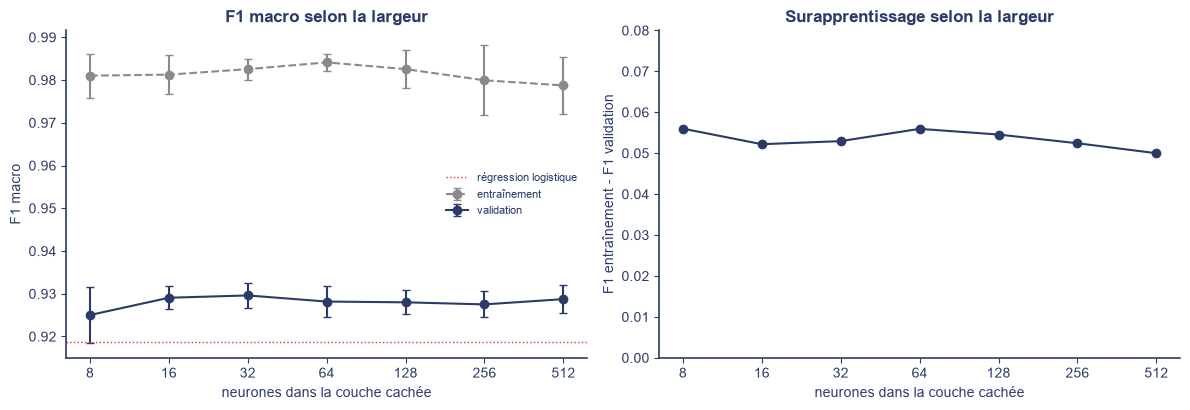

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = tab_largeur["largeur"]

ax[0].errorbar(x, tab_largeur["train_f1"], yerr=tab_largeur["train_f1_std"], color=GRIS_LIGNE, linestyle="--", marker="o", capsize=3, label="entraînement")
ax[0].errorbar(x, tab_largeur["val_f1"], yerr=tab_largeur["val_f1_std"], color=BLEU, marker="o", capsize=3, label="validation")
ax[0].axhline(ref_f1, color=ROUGE, linewidth=1, linestyle=":", label="régression logistique")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(x); ax[0].set_xticklabels(x)
ax[0].set_xlabel("neurones dans la couche cachée"); ax[0].set_ylabel("F1 macro")
ax[0].set_title("F1 macro selon la largeur"); ax[0].legend(frameon=False, fontsize=8)

ax[1].plot(x, tab_largeur["ecart"], color=BLEU, marker="o")
ax[1].set_xscale("log", base=2); ax[1].set_xticks(x); ax[1].set_xticklabels(x)
ax[1].set_xlabel("neurones dans la couche cachée"); ax[1].set_ylabel("F1 entraînement - F1 validation")
ax[1].set_title("Surapprentissage selon la largeur")
ax[1].set_ylim(0, 0.08)
plt.tight_layout(); plt.show()

**rmqs: Impact de la largeur.**

- Avec ReLU, Adam (pas 0,001) et 5 graines, le F1 macro de validation reste compris entre 0,925 et 0,930 quand la couche cachée passe de 8 à 512 neurones (de 4 550 à 290 822 paramètres). Les écarts entre largeurs (au plus 0,005) sont du même ordre que les écarts-types entre graines (0,003 à 0,007) : on ne peut pas conclure qu'une largeur est meilleure qu'une autre. 

- Un réseau de 16 neurones (9 094 paramètres) obtient 0,9291 ± 0,0027, comme celui de 512 neurones (0,9287 ± 0,0033) avec trente fois moins de paramètres. Dès 16 neurones, le MLP dépasse la régression logistique (0,9187) d'environ 0,01, soit environ trois écarts-types.

- Le surapprentissage ne dépend pas non plus de la largeur : par exp dans le graphe 2 : 
    - pas de tendance nette : L’écart entre le F1 d’entraînement et celui de validation reste compris entre 0,050 et 0,056 pour toutes les largeurs, sans tendance croissante -> cause: early stopping


**conclusion** :La taille du réseau n’est pas le facteur limitant. Le plafond d’environ 0,93 vient de la généralisation à de nouveaux volontaires, pas d’un manque de capacité. Il y a donc peu de chances qu’ajouter des couches change beaucoup les choses : c’est la raison d’être de la régularisation .

## Profondeur 

In [10]:
H = 64
archi = [
    # (nom, profondeur, activations)
    ("1 couche : relu",                     1, ["relu"]),
    ("2 couches : relu-relu",               2, ["relu", "relu"]),
    ("2 couches : tanh-tanh",               2, ["tanh", "tanh"]),
    ("2 couches : sigmoid-sigmoid",         2, ["sigmoid", "sigmoid"]),
    ("2 couches : relu-tanh",               2, ["relu", "tanh"]),
    ("2 couches : tanh-relu",               2, ["tanh", "relu"]),
    ("3 couches : relu-relu-relu",          3, ["relu", "relu", "relu"]),
    ("3 couches : tanh-tanh-tanh",          3, ["tanh", "tanh", "tanh"]),
    ("3 couches : relu-tanh-relu",          3, ["relu", "tanh", "relu"]),
    ("3 couches : tanh-relu-tanh",          3, ["tanh", "relu", "tanh"]),
    ("4 couches : relu x4",                 4, ["relu"] * 4),
    ("4 couches : tanh x4",                 4, ["tanh"] * 4),
]

lignes = []
for nom, prof, acts in archi:
    lignes.append(run_seeds(nom, (H,) * prof, acts))
    print(nom, "terminé")
tab_profondeur = pd.DataFrame(lignes)
afficher(tab_profondeur)

1 couche : relu terminé
2 couches : relu-relu terminé
2 couches : tanh-tanh terminé
2 couches : sigmoid-sigmoid terminé
2 couches : relu-tanh terminé
2 couches : tanh-relu terminé
3 couches : relu-relu-relu terminé
3 couches : tanh-tanh-tanh terminé
3 couches : relu-tanh-relu terminé
3 couches : tanh-relu-tanh terminé
4 couches : relu x4 terminé
4 couches : tanh x4 terminé


,configuration,paramètres,val F1,val acc,train F1,écart F1 (train - val),meilleure époque,temps (s)
0,1 couche : relu,36358,0.9282 ± 0.0037,0.9274 ± 0.0035,0.9841,0.0560,8.2,2.9
1,2 couches : relu-relu,40518,0.9252 ± 0.0056,0.9241 ± 0.0053,0.9820,0.0568,6.0,2.7
2,2 couches : tanh-tanh,40518,0.9101 ± 0.0099,0.9099 ± 0.0090,0.9748,0.0647,4.2,2.4
3,2 couches : sigmoid-sigmoid,40518,0.9092 ± 0.0137,0.9093 ± 0.0130,0.9817,0.0726,11.6,5.5
4,2 couches : relu-tanh,40518,0.9245 ± 0.0046,0.9233 ± 0.0044,0.9805,0.0560,5.4,3.9
5,2 couches : tanh-relu,40518,0.9159 ± 0.0070,0.9152 ± 0.0066,0.9720,0.0560,4.0,3.4
6,3 couches : relu-relu-relu,44678,0.9223 ± 0.0045,0.9201 ± 0.0054,0.9772,0.0549,5.2,3.6
7,3 couches : tanh-tanh-tanh,44678,0.9090 ± 0.0107,0.9084 ± 0.0099,0.9682,0.0592,4.2,2.9
8,3 couches : relu-tanh-relu,44678,0.9203 ± 0.0064,0.9183 ± 0.0067,0.9750,0.0547,4.0,2.8
9,3 couches : tanh-relu-tanh,44678,0.9158 ± 0.0043,0.9136 ± 0.0047,0.9739,0.0581,4.4,2.9


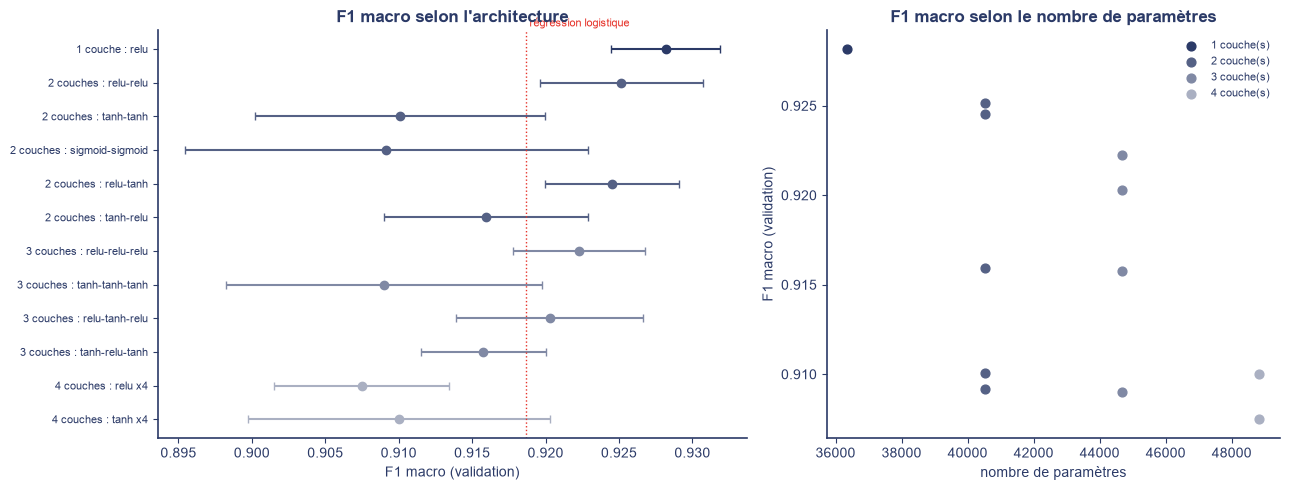

In [11]:
# F1 de validation par architecture (moyenne ± écart-type), colorée par profondeur
couleurs_prof = dict(zip([1, 2, 3, 4], teintes(4, 0.6)))
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})

y = np.arange(len(tab_profondeur))[::-1]
for yi, (_, r) in zip(y, tab_profondeur.iterrows()):
    ax[0].errorbar(r["val_f1"], yi, xerr=r["val_f1_std"], fmt="o", color=couleurs_prof[r["profondeur"]], capsize=3)
ax[0].axvline(ref_f1, color=ROUGE, linewidth=1, linestyle=":")
ax[0].text(ref_f1, len(y) - 0.4, " régression logistique", color=ROUGE, fontsize=8, va="bottom")
ax[0].set_yticks(y); ax[0].set_yticklabels(tab_profondeur["configuration"], fontsize=8)
ax[0].set_xlabel("F1 macro (validation)"); ax[0].set_title("F1 macro selon l'architecture")

for p in [1, 2, 3, 4]:
    d = tab_profondeur[tab_profondeur["profondeur"] == p]
    ax[1].scatter(d["params"], d["val_f1"], color=couleurs_prof[p], s=40, label=f"{p} couche(s)")
ax[1].set_xlabel("nombre de paramètres"); ax[1].set_ylabel("F1 macro (validation)")
ax[1].set_title("F1 macro selon le nombre de paramètres"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Avec des couches de 64 neurones, Adam (pas 0,001) et 5 graines, ajouter des couches n'améliore pas le F1 macro de validation : avec ReLU, il passe de 0,9282 ± 0,0037 (1 couche) à 0,9252 (2 couches), 0,9223 (3 couches) et 0,9075 (4 couches), soit une baisse nette à 4 couches. Les réseaux dont la première couche est tanh ou sigmoid sont moins bons (0,909 à 0,916) et plus variables. Le surapprentissage n'est pas réduit (écart train - validation de 0,055 à 0,073). Seules trois configurations (1 couche ReLU, relu-relu et relu-tanh) dépassent la régression logistique (0,9187) de plus d'un écart-type ; au-delà de deux couches, plus aucune. Le pas d'apprentissage étant le même pour toutes les architectures, ce qui peut pénaliser tanh et sigmoid en profondeur, cette conclusion reste à nuancer.

## Synthèse

In [12]:
tous = pd.concat([tab_largeur.assign(partie="3.1 largeur"), tab_profondeur.assign(partie="3.2 profondeur")], ignore_index=True)
tous = tous.sort_values("val_f1", ascending=False).reset_index(drop=True)
meilleur = tous.iloc[0]
print(f"Meilleure configuration : {meilleur['configuration']} ({meilleur['partie']}) "
      f"| F1 = {meilleur['val_f1']:.4f} ± {meilleur['val_f1_std']:.4f} | {meilleur['params']} paramètres")

# Configurations indiscernables du meilleur : écart de F1 inférieur à l'écart-type du meilleur
proches = tous[(meilleur["val_f1"] - tous["val_f1"]) <= meilleur["val_f1_std"]]
print(f"\nConfigurations à moins d'un écart-type du meilleur ({len(proches)}) :")
display(proches[["partie", "configuration", "params", "val_f1", "val_f1_std", "ecart", "temps_s"]].round(4))

os.makedirs("../results", exist_ok=True)
tous.to_csv("../results/partie3_largeur_profondeur.csv", index=False)

Meilleure configuration : 32 neurones (3.1 largeur) | F1 = 0.9296 ± 0.0028 | 18182 paramètres

Configurations à moins d'un écart-type du meilleur (7) :


,partie,configuration,params,val_f1,val_f1_std,ecart,temps_s
0,3.1 largeur,32 neurones,18182,0.9296,0.0028,0.0530,2.8856
1,3.1 largeur,16 neurones,9094,0.9291,0.0027,0.0522,3.3274
2,3.1 largeur,512 neurones,290822,0.9287,0.0033,0.0500,4.0211
3,3.2 profondeur,1 couche : relu,36358,0.9282,0.0037,0.0560,2.8884
4,3.1 largeur,64 neurones,36358,0.9282,0.0037,0.0560,2.9080
5,3.1 largeur,128 neurones,72710,0.9280,0.0028,0.0546,2.8124
6,3.1 largeur,256 neurones,145414,0.9275,0.0031,0.0524,3.3549


Les largeurs de 16 à 512 neurones donnent des F1 de validation indiscernables (0,9275 à 0,9296, écarts-types d'environ 0,003). Le meilleur score (32 neurones, 0,9296 ± 0,0028) ne se distingue pas des autres au-delà de la variabilité entre graines : sept configurations sont à moins d'un écart-type de lui. Nous gardons donc 64 neurones à une couche comme référence, pour rester comparables à la Version 1, et nous comparons dans la partie 4 des réseaux plus profonds et plus larges, 2×(128,64) et 3×(256,128,64), pour voir si la régularisation permet à la profondeur d'apporter quelque chose.

# Régularisation et robustesse 

Pour comparer deux configurations, on regarde la **différence appariée** : sur chacune des 5 partitions, on calcule F1(config) − F1(référence) et on regarde si elle est positive partout. C'est beaucoup plus sensible qu'une comparaison de moyennes.



In [13]:
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")

set_seed(0)
print("Device :", device, "| torch", torch.__version__)


Device : cpu | torch 2.15.0+cpu



On rassemble les 21 volontaires de train (anciens train + val, déjà standardisés avec les statistiques du train) et on les répartit en 5 groupes avec `GroupKFold`, qui garde chaque volontaire entier dans un seul groupe.


In [14]:
train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")     
all_df = pd.concat([train_df, val_df], ignore_index=True)

feature_cols = [c for c in all_df.columns if c not in ("subject", "Activity")]
classes = sorted(all_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_all = all_df[feature_cols].to_numpy(dtype=np.float32)
y_all = all_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
groups = all_df["subject"].to_numpy()
in_dim = X_all.shape[1]
print("Fenêtres :", X_all.shape, "| volontaires :", len(np.unique(groups)))

N_FOLDS = 5
FOLDS = []
for k, (tr, va) in enumerate(GroupKFold(n_splits=N_FOLDS).split(X_all, y_all, groups)):
    assert not set(groups[tr]) & set(groups[va])            # aucun volontaire des deux côtés
    FOLDS.append({"Xtr": X_all[tr], "ytr": y_all[tr], "Xva": X_all[va], "yva": y_all[va],
                  "val_loader": make_loader(X_all[va], y_all[va], 512),
                  "train_eval_loader": make_loader(X_all[tr], y_all[tr], 512)})
    print(f"partition {k} : {len(tr)} fenêtres d'entraînement ({len(set(groups[tr]))} volontaires), "
          f"{len(va)} de validation ({len(set(groups[va]))} volontaires)")


Fenêtres : (7352, 561) | volontaires : 21
partition 0 : 5932 fenêtres d'entraînement (17 volontaires), 1420 de validation (4 volontaires)
partition 1 : 5932 fenêtres d'entraînement (17 volontaires), 1420 de validation (4 volontaires)
partition 2 : 5935 fenêtres d'entraînement (17 volontaires), 1417 de validation (4 volontaires)
partition 3 : 5942 fenêtres d'entraînement (17 volontaires), 1410 de validation (4 volontaires)
partition 4 : 5667 fenêtres d'entraînement (16 volontaires), 1685 de validation (5 volontaires)


### Réf : régression logistique sur les mêmes partitions


In [15]:
lr_f1 = []
for F in FOLDS:
    m = LogisticRegression(max_iter=500).fit(F["Xtr"], F["ytr"])
    lr_f1.append(f1_score(F["yva"], m.predict(F["Xva"]), average="macro"))
lr_f1 = np.array(lr_f1)
print("F1 macro de la régression logistique par partition :", lr_f1.round(4))
print(f"moyenne = {lr_f1.mean():.4f} | écart-type entre partitions = {lr_f1.std(ddof=1):.4f}")

F1 macro de la régression logistique par partition : [0.8741 0.899  0.9776 0.9689 0.9473]
moyenne = 0.9334 | écart-type entre partitions = 0.0450


Chaque couche cachée enchaîne : `Linear → (BatchNorm) → activation → (Dropout)`.

- **Dropout** : à chaque étape d'entraînement, j'éteins au hasard une partie des neurones (chacun avec une probabilité `p`). Le réseau ne peut donc pas compter sur un neurone en particulier, et il apprend des représentations plus robustes. Je désactive le dropout pendant l'évaluation.
- **BatchNorm** : je recentre et je réduis les sorties de la couche sur chaque mini-batch. Cela rend l'entraînement plus stable, et les petites variations d'un batch à l'autre ont un léger effet régularisant.
- **Weight decay** : j'ajoute une pénalité L2 sur les poids, pour les empêcher de devenir trop grands. Je la règle avec le paramètre `weight_decay` de l'optimiseur.

In [16]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(64,), n_classes=6, act="relu", dropout=0.0, norm=None):
        super().__init__()
        acts = [act] * len(hidden) if isinstance(act, str) else list(act)
        layers, d = [], in_dim
        for h, a in zip(hidden, acts):
            layers.append(nn.Linear(d, h))
            if norm == "bn":
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[a]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        self.features = nn.Sequential(*layers)
        self.out_layer = nn.Linear(d, n_classes)

    def forward(self, x):
        return self.out_layer(self.features(x))

print(MLP(in_dim, (128, 64), n_classes, dropout=0.3, norm="bn"))


MLP(
  (features): Sequential(
    (0): Linear(in_features=561, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
  )
  (out_layer): Linear(in_features=64, out_features=6, bias=True)
)


In [17]:
def train_epoch(model, loader, criterion, optimizer):
    """mode train : dropout actif, BatchNorm sur le batch"""
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb); n += len(yb)
    return total / n

@torch.no_grad()
def evaluate(model, loader):
    """mode eval : dropout éteint, BatchNorm en statistiques apprises"""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

EPOCHS = 40       

def fit(model, optimizer, train_loader, val_loader, epochs=EPOCHS, patience=None):
    criterion = nn.CrossEntropyLoss()
    hist, best_loss, best_state, best_ep, attente = [], float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        tr_loss = train_epoch(model, train_loader, criterion, optimizer)
        va = evaluate(model, val_loader)
        hist.append({"epoch": ep, "train_loss": tr_loss, "val_loss": va["loss"], "val_f1": va["f1"]})
        if patience is None:
            continue
        if va["loss"] < best_loss:
            best_loss, best_ep, attente = va["loss"], ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
        if attente >= patience:
            break
    if patience is None:
        return pd.DataFrame(hist), len(hist)
    model.load_state_dict(best_state)
    return pd.DataFrame(hist), best_ep

def run(cfg, fold, seed=0):
    F = FOLDS[fold]
    set_seed(seed)
    model = MLP(in_dim, cfg["hidden"], n_classes, "relu", cfg.get("dropout", 0.0), cfg.get("norm")).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.get("lr", 1e-3), weight_decay=cfg.get("wd", 0.0))
    train_loader = make_loader(F["Xtr"], F["ytr"], 128, shuffle=True, seed=seed)
    t0 = time.time()
    hist, best_ep = fit(model, optimizer, train_loader, F["val_loader"], cfg.get("epochs", EPOCHS), cfg.get("patience"))
    temps = time.time() - t0
    tr = evaluate(model, F["train_eval_loader"]); va = evaluate(model, F["val_loader"])
    osc = hist["val_f1"].iloc[2:].diff().abs().mean() if len(hist) > 3 else np.nan
    return {"model": model, "hist": hist, "best_epoch": best_ep, "time": temps, "n_params": count_params(model),
            "train_f1": tr["f1"], "val_f1": va["f1"], "val_acc": va["acc"], "val_loss": va["loss"], "osc": osc}

## le protocole de comparaison

Avec la fonction calculer, j'entraîne une liste de configurations sur les 5 partitions (et sur les graines que je choisis) et j'enregistre **une ligne par exécution**. Ensuite, avec "resume", je calcule pour chaque configuration :

- F1 val : je fais la moyenne sur les partitions et je donne l'écart-type entre partitions, qui mesure la variabilité due aux volontaires 

- Δ vs réf : je compare chaque configuration à la référence de la même architecture, sur la même partition (différence appariée). Je rapporte la moyenne ± l'écart-type et je compte les partitions où la configuration fait mieux (par exemple 5/5) 

- écart train − val : je mesure ainsi le surapprentissage ; oscillation : je regarde de combien le F1 de validation varie en moyenne d'une époque à l'autre, pour juger de la stabilité.

Dans cette étape de balayage, je ne mets qu'une graine par partition : les 5 partitions apportent déjà la variabilité.

In [ ]:
os.makedirs("../results", exist_ok=True)

def calculer(fichier, configs, seeds=(0,)):
    chemin = f"../results/{fichier}"
    if os.path.exists(chemin):
        print("rechargé depuis", chemin)
        return pd.read_csv(chemin)
    lignes = []
    for nom, cfg, meta in configs:
        t0 = time.time()
        for k in range(N_FOLDS):
            for s in seeds:
                r = run(cfg, k, s)
                lignes.append({**meta, "configuration": nom, "fold": k, "seed": s, "params": r["n_params"],
                               "val_f1": r["val_f1"], "val_acc": r["val_acc"], "train_f1": r["train_f1"],
                               "val_loss": r["val_loss"], "osc": r["osc"], "best_epoch": r["best_epoch"], "time": r["time"]})
        print(f"{nom} : {time.time() - t0:.0f} s")
    tab = pd.DataFrame(lignes)
    tab.to_csv(chemin, index=False)
    return tab

def resume(long, refs):
    base_ref = (refs[refs["valeur"] == "référence"].groupby(["base", "fold"])["val_f1"].mean())
    lignes = []
    for nom, d in long.groupby("configuration", sort=False):
        b = d["base"].iloc[0]
        par_fold = d.groupby("fold")["val_f1"].mean()
        delta = par_fold - base_ref.loc[b].reindex(par_fold.index)
        std_seeds = d.groupby("fold")["val_f1"].std(ddof=1).mean() if d["seed"].nunique() > 1 else np.nan
        lignes.append({"configuration": nom, "base": b, "technique": d["technique"].iloc[0], "valeur": d["valeur"].iloc[0],
            "params": d["params"].iloc[0], "val_f1": par_fold.mean(), "std_partitions": par_fold.std(ddof=1), "std_graines": std_seeds,
            "delta": delta.mean(), "delta_std": delta.std(ddof=1), "mieux": int((delta > 0).sum()), "n_part": len(delta),
            "train_f1": d["train_f1"].mean(), "ecart": (d["train_f1"] - d["val_f1"]).mean(),
            "oscillation": d["osc"].mean(), "meilleure_epoque": d["best_epoch"].mean(), "temps_s": d["time"].mean()})
    return pd.DataFrame(lignes)

def afficher(res):
    out = pd.DataFrame({"configuration": res["configuration"], "paramètres": res["params"],
        "val F1 (± std partitions)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(res["val_f1"], res["std_partitions"])],
        "Δ vs réf. (appariée)": [f"{d:+.4f} ± {s:.4f}" for d, s in zip(res["delta"], res["delta_std"])],
        "partitions où mieux": [f"{m}/{n}" for m, n in zip(res["mieux"], res["n_part"])],
        "train F1": res["train_f1"].round(4), "écart train - val": res["ecart"].round(4),
        "oscillation": res["oscillation"].round(4), "temps (s)": res["temps_s"].round(1)})
    display(out.reset_index(drop=True))

BASES = {"1x64": (64,), "2x(128,64)": (128, 64), "3x(256,128,64)": (256, 128, 64)}
COUL_BASE = {"1x64": BLEU, "2x(128,64)": ROUGE, "3x(256,128,64)": GRIS_LIGNE}

## Réf : 3 profondeurs sans régularisation

40 époques fixes, ReLU, Adam à 0,001. Ce sont nos **références appariées** pour tout le reste.

In [19]:
configs = [(f"{b} : référence", {"hidden": h}, {"base": b, "technique": "référence", "valeur": "référence"})
           for b, h in BASES.items()]
long_ref = calculer("partie4b_reference.csv", configs)
res_ref = resume(long_ref, long_ref)
afficher(res_ref)
print(f"Régression logistique : F1 = {lr_f1.mean():.4f} ± {lr_f1.std(ddof=1):.4f} (entre partitions)")
d_lr = [(long_ref[(long_ref.base == b)].groupby("fold")["val_f1"].mean() - lr_f1).mean() for b in BASES]
print("Écart moyen MLP sans régularisation - régression logistique :", dict(zip(BASES, np.round(d_lr, 4))))

rechargé depuis ../results/partie4b_reference.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : référence,36358,0.9284 ± 0.0427,+0.0000 ± 0.0000,0/5,0.9995,0.0711,0.0043,5.0
1,"2x(128,64) : référence",80582,0.9275 ± 0.0459,+0.0000 ± 0.0000,0/5,1.0000,0.0725,0.0053,6.4
2,"3x(256,128,64) : référence",185414,0.9281 ± 0.0445,+0.0000 ± 0.0000,0/5,1.0000,0.0719,0.0051,9.3


Régression logistique : F1 = 0.9334 ± 0.0450 (entre partitions)
Écart moyen MLP sans régularisation - régression logistique : {'1x64': np.float64(-0.005), '2x(128,64)': np.float64(-0.0059), '3x(256,128,64)': np.float64(-0.0053)}


### courbes d'apprentissage sans arrêt précoce


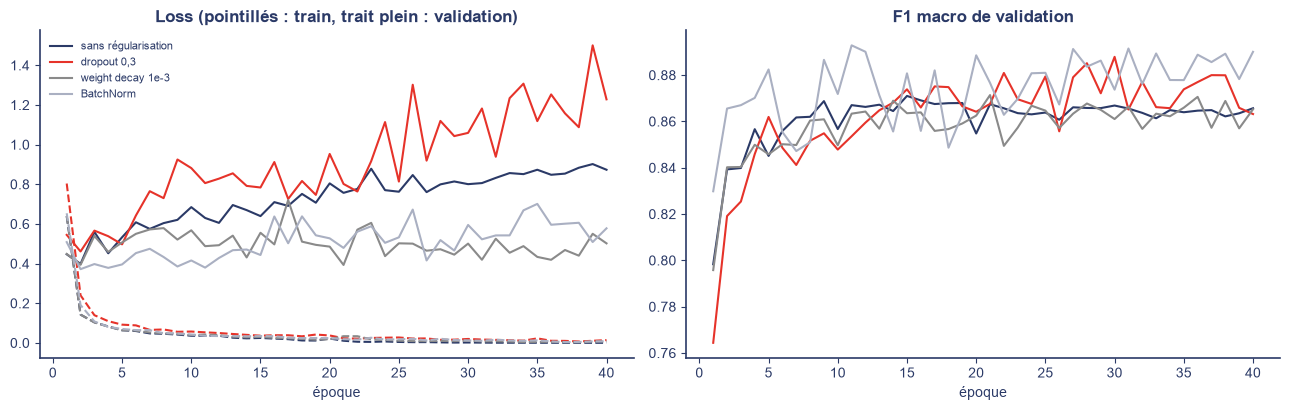

In [20]:
couleurs = [BLEU, ROUGE, GRIS_LIGNE, teintes(3, 0.6)[2]]
exemples = [("sans régularisation", {}), ("dropout 0,3", {"dropout": 0.3}),
            ("weight decay 1e-3", {"wd": 1e-3}), ("BatchNorm", {"norm": "bn"})]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for (nom, extra), col in zip(exemples, couleurs):
    h = run({"hidden": (128, 64), **extra}, fold=0, seed=0)["hist"]
    ax[0].plot(h["epoch"], h["train_loss"], "--", color=col)
    ax[0].plot(h["epoch"], h["val_loss"], "-", color=col, label=nom)
    ax[1].plot(h["epoch"], h["val_f1"], "-", color=col, label=nom)
ax[0].set_title("Loss (pointillés : train, trait plein : validation)")
ax[1].set_title("F1 macro de validation")
for a in ax:
    a.set_xlabel("époque")
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

##  Dropout (p = 0,1 ; 0,3 ; 0,5)

Sur chacune des trois profondeurs.

In [21]:
configs = [(f"{b} : dropout {p}", {"hidden": h, "dropout": p}, {"base": b, "technique": "dropout", "valeur": str(p)})
           for b, h in BASES.items() for p in [0.1, 0.3, 0.5]]
long_drop = calculer("partie4b_dropout.csv", configs)
res_drop = resume(long_drop, long_ref)
afficher(res_drop)

rechargé depuis ../results/partie4b_dropout.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : dropout 0.1,36358,0.9251 ± 0.0491,-0.0032 ± 0.0073,2/5,0.9994,0.0743,0.0050,5.3
1,1x64 : dropout 0.3,36358,0.9292 ± 0.0469,+0.0009 ± 0.0069,4/5,0.9993,0.0701,0.0045,5.2
2,1x64 : dropout 0.5,36358,0.9282 ± 0.0509,-0.0001 ± 0.0095,3/5,0.9976,0.0694,0.0047,5.3
3,"2x(128,64) : dropout 0.1",80582,0.9289 ± 0.0477,+0.0014 ± 0.0105,3/5,0.9992,0.0703,0.0066,7.3
4,"2x(128,64) : dropout 0.3",80582,0.9249 ± 0.0497,-0.0025 ± 0.0095,2/5,0.9989,0.0740,0.0067,7.2
5,"2x(128,64) : dropout 0.5",80582,0.9330 ± 0.0415,+0.0055 ± 0.0103,3/5,0.9975,0.0645,0.0065,8.8
6,"3x(256,128,64) : dropout 0.1",185414,0.9276 ± 0.0463,-0.0005 ± 0.0029,2/5,0.9988,0.0712,0.0088,11.5
7,"3x(256,128,64) : dropout 0.3",185414,0.9286 ± 0.0484,+0.0005 ± 0.0070,2/5,0.9986,0.0700,0.0087,11.3
8,"3x(256,128,64) : dropout 0.5",185414,0.9315 ± 0.0451,+0.0034 ± 0.0062,3/5,0.9971,0.0656,0.0089,11.4


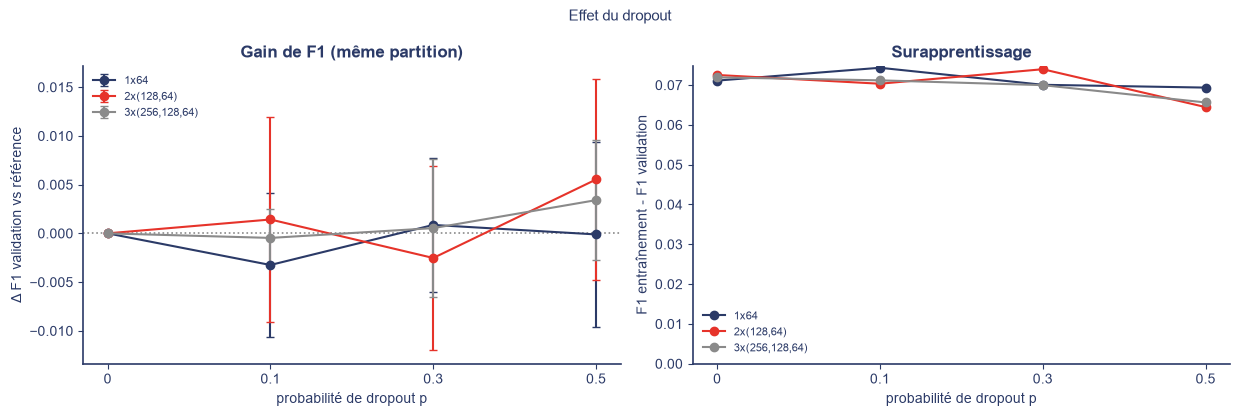

In [ ]:
def tracer_effet(res, valeurs, titre, xlabel):
    ref = res_ref.set_index("base")
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
    pos = np.arange(len(valeurs) + 1)
    for b in BASES:
        d = res[res["base"] == b].assign(valeur=lambda t: t["valeur"].astype(str)).set_index("valeur").reindex([str(v) for v in valeurs])
        ax[0].errorbar(pos, [0] + list(d["delta"]), yerr=[0] + list(d["delta_std"]), color=COUL_BASE[b],
                       marker="o", capsize=3, label=b)
        ax[1].plot(pos, [ref.loc[b, "ecart"]] + list(d["ecart"]), color=COUL_BASE[b], marker="o", label=b)
    ax[0].axhline(0, color=GRIS_LIGNE, linestyle=":", linewidth=1.2)
    for a, yl, t in [(ax[0], "Δ F1 validation vs référence", "Gain de F1 (même partition)"),
                     (ax[1], "F1 entraînement - F1 validation", "Surapprentissage")]:
        a.set_xticks(pos); a.set_xticklabels(["0"] + [str(v) for v in valeurs]); a.set_xlabel(xlabel)
        a.set_ylabel(yl); a.set_title(t); a.legend(frameon=False, fontsize=8)
    ax[1].set_ylim(0, None)
    fig.suptitle(titre, fontsize=11); plt.tight_layout(); plt.show()

tracer_effet(res_drop, ["0.1", "0.3", "0.5"], "Effet du dropout", "probabilité de dropout p")

Le dropout n'apporte pas de gain mesurable : les gains Δ vont de −0,003 à +0,006, toujours plus petits que leur écart-type (0,003 à 0,010), et ne sont jamais positifs sur les 5 partitions (au mieux 4/5). Le meilleur résultat vient de p = 0,5 sur les réseaux profonds (2×(128,64) : +0,0055 ; 3×(256,128,64) : +0,0034), mais avec seulement 3 partitions sur 5.

 L'écart train − validation ne baisse un peu qu'à p = 0,5 (de ≈ 0,072 à ≈ 0,065 pour les réseaux profonds), sans tendance nette pour p = 0,1 et 0,3. Aucun signe de sous-apprentissage, même à p = 0,5. 
 Le dropout ne stabilise pas non plus l'entraînement : l'oscillation augmente avec la profondeur (3 couches : de 0,0051 à ≈ 0,0088).

## Weight decay (régularisation L2)

rechargé depuis ../results/partie4b_weight_decay.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : weight decay 0.0001,36358,0.9300 ± 0.0432,+0.0016 ± 0.0018,4/5,0.9992,0.0692,0.0047,5.1
1,1x64 : weight decay 0.001,36358,0.9281 ± 0.0485,-0.0002 ± 0.0063,3/5,0.9985,0.0704,0.0056,4.9
2,1x64 : weight decay 0.01,36358,0.9211 ± 0.0515,-0.0073 ± 0.0120,2/5,0.9872,0.0662,0.0078,5.1
3,"2x(128,64) : weight decay 0.0001",80582,0.9273 ± 0.0474,-0.0002 ± 0.0047,2/5,1.0000,0.0727,0.0053,6.4
4,"2x(128,64) : weight decay 0.001",80582,0.9296 ± 0.0465,+0.0022 ± 0.0045,2/5,0.9998,0.0702,0.0082,6.7
5,"2x(128,64) : weight decay 0.01",80582,0.9223 ± 0.0534,-0.0052 ± 0.0110,2/5,0.9900,0.0677,0.0090,6.5
6,"3x(256,128,64) : weight decay 0.0001",185414,0.9293 ± 0.0464,+0.0013 ± 0.0024,4/5,1.0000,0.0707,0.0069,9.5
7,"3x(256,128,64) : weight decay 0.001",185414,0.9233 ± 0.0430,-0.0047 ± 0.0052,1/5,0.9970,0.0736,0.0111,9.6
8,"3x(256,128,64) : weight decay 0.01",185414,0.9205 ± 0.0556,-0.0076 ± 0.0114,2/5,0.9923,0.0718,0.0121,9.7


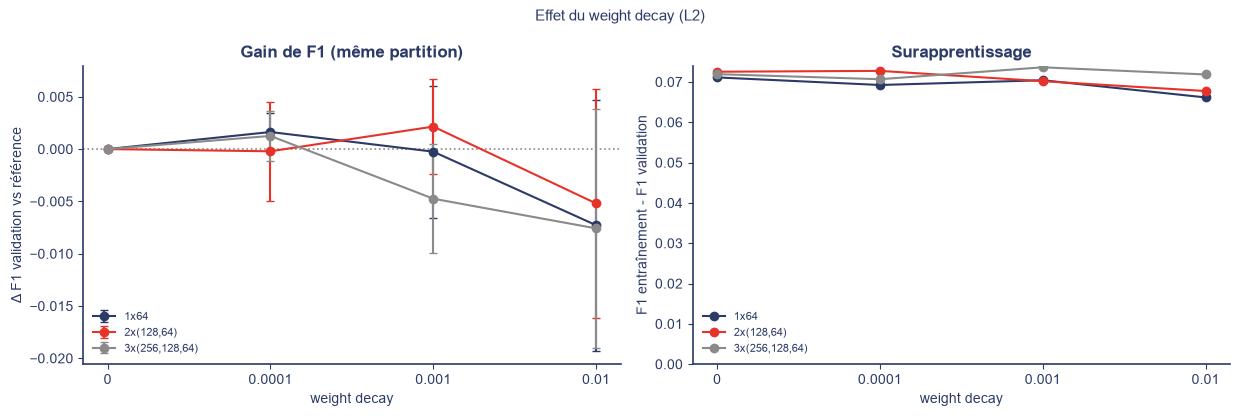

In [23]:
WDS = [1e-4, 1e-3, 1e-2]
configs = [(f"{b} : weight decay {wd:g}", {"hidden": h, "wd": wd}, {"base": b, "technique": "weight decay", "valeur": f"{wd:g}"})
           for b, h in BASES.items() for wd in WDS]
long_wd = calculer("partie4b_weight_decay.csv", configs)
res_wd = resume(long_wd, long_ref)
afficher(res_wd)
tracer_effet(res_wd, [f"{w:g}" for w in WDS], "Effet du weight decay (L2)", "weight decay")

Le weight decay n'améliore le F1 de validation que très faiblement, et seulement à 10⁻⁴ : +0,0016 pour 1×64 et +0,0013 pour 3×(256,128,64), positifs sur 4 partitions sur 5, mais ce sont des gains minuscules. À 10⁻³ l'effet est nul ou négatif (de −0,005 à +0,002), et à 10⁻² il est franchement négatif pour les trois réseaux (de −0,005 à −0,008) : le F1 d'entraînement baisse (≈ 0,99 au lieu de 1,00), signe que la pénalité devient trop forte et commence à empêcher d'apprendre. 
- L'écart train − validation ne diminue pas de façon nette (0,066 à 0,074 contre ≈ 0,072 sans pénalité) et les réseaux profonds n'en profitent pas davantage.
- L'oscillation augmente avec la pénalité (3 couches : de 0,0051 à 0,0121 à 10⁻²) : l'entraînement devient moins stable.

## Batch Normalization

In [24]:
configs = [(f"{b} : BatchNorm", {"hidden": h, "norm": "bn"}, {"base": b, "technique": "BatchNorm", "valeur": "bn"})
           for b, h in BASES.items()]
long_bn = calculer("partie4b_batchnorm.csv", configs)
res_bn = resume(long_bn, long_ref)
afficher(res_bn)

rechargé depuis ../results/partie4b_batchnorm.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : BatchNorm,36486,0.9302 ± 0.0464,+0.0018 ± 0.0160,3/5,0.9998,0.0696,0.0072,5.5
1,"2x(128,64) : BatchNorm",80966,0.9313 ± 0.0354,+0.0038 ± 0.0121,2/5,0.9964,0.0651,0.0114,7.4
2,"3x(256,128,64) : BatchNorm",186310,0.9304 ± 0.0369,+0.0023 ± 0.0094,3/5,0.9964,0.0659,0.0153,10.7


La BatchNorm donne un petit gain de F1 (+0,002 à +0,004), mais très inférieur à son écart-type (0,009 à 0,016) : il n'est pas significatif. Elle réduit un peu l'écart train − validation des réseaux profonds (0,065 contre ≈ 0,072). En revanche, l'oscillation de la validation augmente avec la profondeur (3 couches : de 0,0051 à 0,0153) : elle ne stabilise pas l'entraînement ici.

## Arrêt précoce



In [25]:
configs = [(f"{b} : arrêt précoce, patience {pat}", {"hidden": h, "patience": pat},
            {"base": b, "technique": "arrêt précoce", "valeur": f"patience {pat}"})
           for b, h in BASES.items() for pat in [5, 10, 20]]
long_es = calculer("partie4b_arret_precoce.csv", configs)
res_es = resume(long_es, long_ref)
afficher(res_es.assign(**{}))
print("Meilleure époque moyenne :", res_es.groupby("valeur")["meilleure_epoque"].mean().round(1).to_dict())

rechargé depuis ../results/partie4b_arret_precoce.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,"1x64 : arrêt précoce, patience 5",36358,0.9287 ± 0.0527,+0.0003 ± 0.0102,3/5,0.9863,0.0576,0.0054,1.8
1,"1x64 : arrêt précoce, patience 10",36358,0.9280 ± 0.0518,-0.0004 ± 0.0095,3/5,0.9870,0.0590,0.0046,2.7
2,"1x64 : arrêt précoce, patience 20",36358,0.9280 ± 0.0518,-0.0004 ± 0.0095,3/5,0.9870,0.0590,0.0044,3.8
3,"2x(128,64) : arrêt précoce, patience 5",80582,0.9203 ± 0.0593,-0.0072 ± 0.0138,2/5,0.9789,0.0586,0.0071,1.5
4,"2x(128,64) : arrêt précoce, patience 10",80582,0.9209 ± 0.0602,-0.0066 ± 0.0146,2/5,0.9802,0.0593,0.0076,2.5
5,"2x(128,64) : arrêt précoce, patience 20",80582,0.9209 ± 0.0602,-0.0066 ± 0.0146,2/5,0.9802,0.0593,0.0063,4.0
6,"3x(256,128,64) : arrêt précoce, patience 5",185414,0.9210 ± 0.0649,-0.0071 ± 0.0248,4/5,0.9754,0.0544,0.0071,2.5
7,"3x(256,128,64) : arrêt précoce, patience 10",185414,0.9210 ± 0.0649,-0.0071 ± 0.0248,4/5,0.9754,0.0544,0.0072,3.7
8,"3x(256,128,64) : arrêt précoce, patience 20",185414,0.9210 ± 0.0649,-0.0071 ± 0.0248,4/5,0.9754,0.0544,0.0069,6.0


Meilleure époque moyenne : {'patience 10': 7.5, 'patience 20': 7.5, 'patience 5': 6.3}


L'arrêt précoce ne change pas le F1 : −0,0004 à +0,0003 pour le 1x64, et −0,007 pour les réseaux plus profonds, toujours très inférieur à l'écart-type (0,05 à 0,06). Il réduit légèrement l'écart train − validation (≈ 0,059 contre ≈ 0,072 sans régularisation) et divise le temps d'entraînement. La patience n'a presque aucun effet : 10 et 20 donnent des résultats identiques. Le meilleur modèle est atteint tôt, vers l'époque 6 à 8.

## Combinaisons


In [26]:
p_best  = res_drop.groupby("valeur")["delta"].mean().idxmax()
wd_best = res_wd.groupby("valeur")["delta"].mean().idxmax()
print(f"Dropout retenu : p = {p_best} | weight decay retenu : {wd_best}")
P, WD = float(p_best), float(wd_best)

combos = {"dropout + weight decay": {"dropout": P, "wd": WD},
          "BatchNorm + dropout": {"norm": "bn", "dropout": P},
          "BatchNorm + dropout + weight decay": {"norm": "bn", "dropout": P, "wd": WD}}
configs = [(f"{b} : {nom}", {"hidden": h, **extra}, {"base": b, "technique": "combinaison", "valeur": nom})
           for b, h in BASES.items() for nom, extra in combos.items()]
long_combo = calculer("partie4b_combinaisons.csv", configs)
res_combo = resume(long_combo, long_ref)
afficher(res_combo)

Dropout retenu : p = 0.5 | weight decay retenu : 0.0001
rechargé depuis ../results/partie4b_combinaisons.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : dropout + weight decay,36358,0.9290 ± 0.0546,+0.0007 ± 0.0136,3/5,0.9978,0.0687,0.0046,5.5
1,1x64 : BatchNorm + dropout,36486,0.9298 ± 0.0455,+0.0014 ± 0.0101,3/5,0.9964,0.0666,0.0060,5.8
2,1x64 : BatchNorm + dropout + weight decay,36486,0.9305 ± 0.0477,+0.0021 ± 0.0147,4/5,0.9959,0.0654,0.0060,5.9
3,"2x(128,64) : dropout + weight decay",80582,0.9245 ± 0.0456,-0.0030 ± 0.0123,2/5,0.9970,0.0725,0.0069,7.4
4,"2x(128,64) : BatchNorm + dropout",80966,0.9331 ± 0.0450,+0.0056 ± 0.0068,3/5,0.9953,0.0623,0.0081,8.3
5,"2x(128,64) : BatchNorm + dropout + weight decay",80966,0.9331 ± 0.0390,+0.0056 ± 0.0111,3/5,0.9959,0.0628,0.0068,8.4
6,"3x(256,128,64) : dropout + weight decay",185414,0.9222 ± 0.0515,-0.0059 ± 0.0095,2/5,0.9955,0.0733,0.0080,11.5
7,"3x(256,128,64) : BatchNorm + dropout",186310,0.9307 ± 0.0503,+0.0026 ± 0.0090,2/5,0.9959,0.0652,0.0088,12.8
8,"3x(256,128,64) : BatchNorm + dropout + weight ...",186310,0.9346 ± 0.0415,+0.0065 ± 0.0095,4/5,0.9940,0.0594,0.0091,17.7


- Effet des méthodes sur la stabilité et la généralisation.**

Les combinaisons avec BatchNorm donnent les meilleurs F1 sur les réseaux profonds (2x : 0,9331, +0,0056 ; 3x avec les trois techniques : 0,9346, +0,0065, mieux sur 4/5 partitions). Ces gains restent petits face à l'écart-type entre partitions (≈ 0,04) : la tendance est cohérente, mais pas significative. Dropout + weight decay sans BatchNorm ne rapporte rien, voire dégrade les réseaux profonds (−0,003 à −0,006). Le réseau à une couche profite peu (+0,0007 à +0,0021), alors que les réseaux profonds profitent davantage. L'écart train − validation diminue avec BatchNorm (≈ 0,059 à 0,065 contre ≈ 0,072), mais l'oscillation augmente (jusqu'à 0,009) : on gagne un peu en généralisation, pas en stabilité.

## Configurations retenues et confirmation avec plusieurs graines


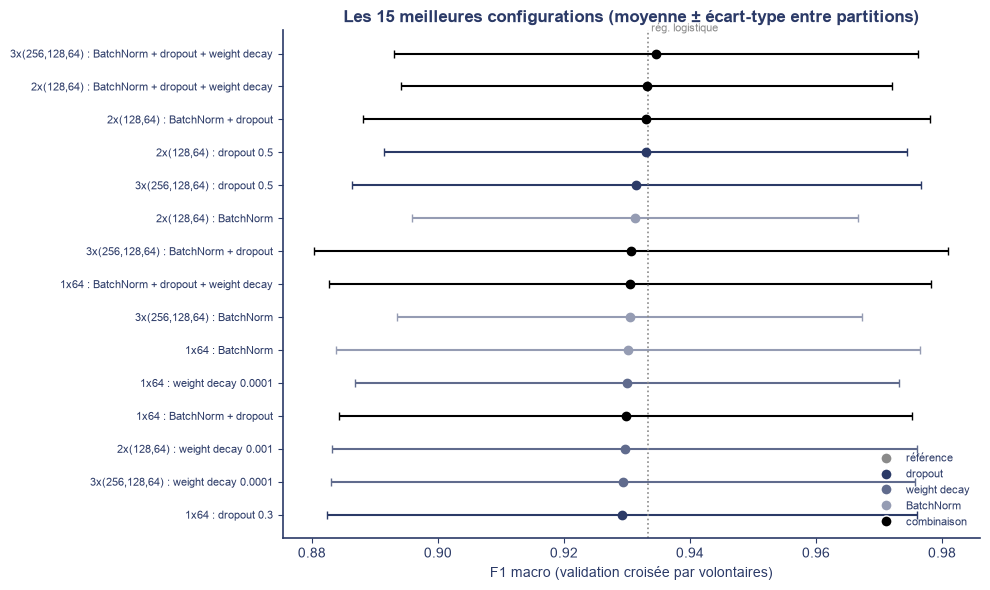

,configuration,params,val_f1,std_partitions,delta,mieux,ecart,oscillation
0,"3x(256,128,64) : BatchNorm + dropout + weight ...",186310,0.9346,0.0415,0.0065,4,0.0594,0.0091
1,"2x(128,64) : BatchNorm + dropout + weight decay",80966,0.9331,0.0390,0.0056,3,0.0628,0.0068
2,"2x(128,64) : BatchNorm + dropout",80966,0.9331,0.0450,0.0056,3,0.0623,0.0081
3,"2x(128,64) : dropout 0.5",80582,0.9330,0.0415,0.0055,3,0.0645,0.0065
4,"3x(256,128,64) : dropout 0.5",185414,0.9315,0.0451,0.0034,3,0.0656,0.0089
5,"2x(128,64) : BatchNorm",80966,0.9313,0.0354,0.0038,2,0.0651,0.0114
6,"3x(256,128,64) : BatchNorm + dropout",186310,0.9307,0.0503,0.0026,2,0.0652,0.0088
7,1x64 : BatchNorm + dropout + weight decay,36486,0.9305,0.0477,0.0021,4,0.0654,0.0060


In [ ]:
res_all = pd.concat([res_ref, res_drop, res_wd, res_bn, res_combo], ignore_index=True)
res_all = res_all.sort_values("val_f1", ascending=False).reset_index(drop=True)

types = ["référence", "dropout", "weight decay", "BatchNorm", "combinaison"]
coul = dict(zip(types, [GRIS_LIGNE, BLEU, teintes(3, 0.5)[1], teintes(3, 0.5)[2], "#000000"]))
top = res_all.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
for i, (_, r) in enumerate(top.iterrows()):
    ax.errorbar(r["val_f1"], i, xerr=r["std_partitions"], fmt="o", color=coul[r["technique"]], capsize=3)
ax.axvline(lr_f1.mean(), color=GRIS_LIGNE, linestyle=":", linewidth=1.2)
ax.text(lr_f1.mean(), len(top) - 0.4, " rég. logistique", color=GRIS_LIGNE, fontsize=8, va="bottom")
ax.set_yticks(range(len(top))); ax.set_yticklabels(top["configuration"], fontsize=8)
ax.set_xlabel("F1 macro (validation croisée par volontaires)")
ax.set_title("Les 15 meilleures configurations (moyenne ± écart-type entre partitions)")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=coul[t], markersize=8, label=t) for t in types]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

display(res_all.head(8)[["configuration", "params", "val_f1", "std_partitions", "delta", "mieux", "ecart", "oscillation"]].round(4))

In [ ]:
def cfg_de(nom):
    b, reste = nom.split(" : ")
    cfg = {"hidden": BASES[b]}
    if "dropout" in reste and "combinaison" not in reste and "+" not in reste: cfg["dropout"] = float(reste.split()[-1])
    if reste.startswith("weight decay"): cfg["wd"] = float(reste.split()[-1])
    if reste == "BatchNorm": cfg["norm"] = "bn"
    if reste.startswith("arrêt précoce"): cfg["patience"] = int(reste.split()[-1])
    if "+" in reste:
        if "dropout" in reste: cfg["dropout"] = P
        if "weight decay" in reste: cfg["wd"] = WD
        if "BatchNorm" in reste: cfg["norm"] = "bn"
    return cfg

retenues = [n for n in res_all["configuration"] if "référence" not in n][:3]
print("Configurations retenues :", retenues)
configs = [("1x64 : référence", {"hidden": (64,)}, {"base": "1x64", "technique": "référence", "valeur": "référence"}),
           ("1x64 : référence + arrêt précoce", {"hidden": (64,), "patience": 10},
            {"base": "1x64", "technique": "référence", "valeur": "référence + ES"})]
for n in retenues:
    b = n.split(" : ")[0]
    meta = res_all.set_index("configuration").loc[n]
    configs.append((n, cfg_de(n), {"base": b, "technique": meta["technique"], "valeur": meta["valeur"]}))
    configs.append((n + " + arrêt précoce", {**cfg_de(n), "patience": 10},
                    {"base": b, "technique": meta["technique"], "valeur": meta["valeur"] + " + ES"}))
long_fin = calculer("partie4b_retenues_3graines.csv", configs, seeds=(0, 1, 2))
res_fin = resume(long_fin, long_ref)
afficher(res_fin)
print("std_graines (moyenne sur partitions) :", res_fin.set_index("configuration")["std_graines"].round(4).to_dict())

Configurations retenues : ['3x(256,128,64) : BatchNorm + dropout + weight decay', '2x(128,64) : BatchNorm + dropout + weight decay', '2x(128,64) : BatchNorm + dropout']
rechargé depuis ../results/partie4b_retenues_3graines.csv


,configuration,paramètres,val F1 (± std partitions),Δ vs réf. (appariée),partitions où mieux,train F1,écart train - val,oscillation,temps (s)
0,1x64 : référence,36358,0.9299 ± 0.0438,+0.0016 ± 0.0023,4/5,0.9991,0.0692,0.0042,6.3
1,1x64 : référence + arrêt précoce,36358,0.9252 ± 0.0552,-0.0031 ± 0.0130,2/5,0.9854,0.0602,0.0045,2.6
2,"3x(256,128,64) : BatchNorm + dropout + weight ...",186310,0.9311 ± 0.0447,+0.0030 ± 0.0095,3/5,0.9949,0.0638,0.0093,14.0
3,"3x(256,128,64) : BatchNorm + dropout + weight ...",186310,0.9306 ± 0.0556,+0.0026 ± 0.0156,4/5,0.9843,0.0536,0.0096,8.9
4,"2x(128,64) : BatchNorm + dropout + weight decay",80966,0.9308 ± 0.0464,+0.0033 ± 0.0102,3/5,0.9957,0.0649,0.0079,9.0
5,"2x(128,64) : BatchNorm + dropout + weight deca...",80966,0.9313 ± 0.0542,+0.0038 ± 0.0109,3/5,0.9864,0.0552,0.0084,5.3
6,"2x(128,64) : BatchNorm + dropout",80966,0.9316 ± 0.0473,+0.0041 ± 0.0103,3/5,0.9957,0.0641,0.0085,13.1
7,"2x(128,64) : BatchNorm + dropout + arrêt précoce",80966,0.9312 ± 0.0528,+0.0038 ± 0.0104,3/5,0.9865,0.0553,0.0087,6.3


std_graines (moyenne sur partitions) : {'1x64 : référence': 0.0038, '1x64 : référence + arrêt précoce': 0.0034, '3x(256,128,64) : BatchNorm + dropout + weight decay': 0.0069, '3x(256,128,64) : BatchNorm + dropout + weight decay + arrêt précoce': 0.0088, '2x(128,64) : BatchNorm + dropout + weight decay': 0.0062, '2x(128,64) : BatchNorm + dropout + weight decay + arrêt précoce': 0.0058, '2x(128,64) : BatchNorm + dropout': 0.006, '2x(128,64) : BatchNorm + dropout + arrêt précoce': 0.004}


In [29]:
pd.concat([res_ref, res_drop, res_wd, res_bn, res_es, res_combo]).to_csv("../results/partie4b_toutes_configurations.csv", index=False)
meilleur = res_all.iloc[0]
print(f"Meilleure configuration : {meilleur['configuration']} | F1 = {meilleur['val_f1']:.4f} ± {meilleur['std_partitions']:.4f} "
      f"| {meilleur['params']} paramètres | gain vs sa référence = {meilleur['delta']:+.4f}")

Meilleure configuration : 3x(256,128,64) : BatchNorm + dropout + weight decay | F1 = 0.9346 ± 0.0415 | 186310 paramètres | gain vs sa référence = +0.0065


## Bilan de la partie 

Aucune technique ne donne de gain significatif (+0,002 à +0,006, contre un écart-type de ≈ 0,04). BatchNorm est la plus régulière et réduit un peu l'écart train − validation. Les réseaux profonds profitent un peu plus de la régularisation que le 1x64. La régression logistique (≈ 0,933) fait aussi bien. Je retiens 1x64 de référence, 2x(128,64) BatchNorm + dropout, et 3x(256,128,64) BatchNorm + dropout + weight decay (la meilleure, 0,9346). Limites : 21 volontaires, arrêt précoce choisi sur la validation, lr fixé.


# Courbes d'apprentissage et évaluation finale


In [30]:
import json

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")

cmap_bleu = sns.light_palette(BLEU, as_cmap=True)

set_seed(0)
print("Device :", device)


Device : cpu


In [31]:
CONFIGS = [
    {"nom": "Version 2a : 2 couches (128,64), BatchNorm + dropout 0,5", "version": 2,
     "hidden": (128, 64), "dropout": 0.5, "norm": "bn", "wd": 0.0,
     "nom_cv": "2x(128,64) : BatchNorm + dropout"},
    {"nom": "Version 2b : 3 couches (256,128,64), BatchNorm + dropout 0,5 + weight decay 1e-4", "version": 2,
     "hidden": (256, 128, 64), "dropout": 0.5, "norm": "bn", "wd": 1e-4,
     "nom_cv": "3x(256,128,64) : BatchNorm + dropout + weight decay"},
]

cv = pd.read_csv("../results/partie4b_retenues_3graines.csv")
lignes = []
for cfg in CONFIGS:
    avec_es = cv[cv["configuration"] == cfg["nom_cv"] + " + arrêt précoce"]
    sans_es = cv[cv["configuration"] == cfg["nom_cv"]]
    if avec_es.empty:
        raise ValueError(f"Configuration absente du CSV de la partie 4 : {cfg['nom_cv']!r}. Corrige 'nom_cv'.")
    cfg["epochs"] = max(5, int(round(avec_es["best_epoch"].median())))
    cfg["f1_cv"] = avec_es["val_f1"].mean()
    cfg["f1_cv_std"] = avec_es.groupby("fold")["val_f1"].mean().std(ddof=1)
    lignes.append({"configuration": cfg["nom"], "époques (médiane CV)": cfg["epochs"],
                   "F1 validation croisée": f"{cfg['f1_cv']:.4f} ± {cfg['f1_cv_std']:.4f}"})
display(pd.DataFrame(lignes))

,configuration,époques (médiane CV),F1 validation croisée
0,"Version 2a : 2 couches (128,64), BatchNorm + d...",10,0.9312 ± 0.0528
1,"Version 2b : 3 couches (256,128,64), BatchNorm...",16,0.9306 ± 0.0556


In [32]:
train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")
all_df = pd.concat([train_df, val_df], ignore_index=True)

feat = [c for c in all_df.columns if c not in ("subject", "Activity")]
classes = sorted(all_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_all = all_df[feat].to_numpy(dtype=np.float32)
y_all = all_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
subj  = all_df["subject"].to_numpy()
in_dim = X_all.shape[1]

# Découpage de la partie 2 (utilisé seulement pour les courbes 5.1)
val_subjects = json.load(open("../data/split_volontaires.json"))["val_subjects"]
est_val = np.isin(subj, val_subjects)
X_tr, y_tr, X_va, y_va = X_all[~est_val], y_all[~est_val], X_all[est_val], y_all[est_val]
print("21 volontaires :", X_all.shape, "| courbes 5.1 : train", X_tr.shape[0], "/ val", X_va.shape[0],
      "| volontaires de validation :", val_subjects)


21 volontaires : (7352, 561) | courbes 5.1 : train 5657 / val 1695 | volontaires de validation : [8, 11, 16, 19, 23]


In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(64,), n_classes=6, act="relu", dropout=0.0, norm=None):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if norm == "bn":
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[act]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        self.features = nn.Sequential(*layers)
        self.out_layer = nn.Linear(d, n_classes)

    def forward(self, x):
        return self.out_layer(self.features(x))

def build(cfg):
    return MLP(in_dim, cfg["hidden"], n_classes, "relu", cfg["dropout"], cfg["norm"]).to(device)

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb); n += len(yb)
    return total / n

@torch.no_grad()
def evaluate(model, loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro"), "pred": p}

def entrainer(cfg, X, y, epochs, seed, suivi=None):
    
    set_seed(seed)
    model = build(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=cfg["wd"])
    crit = nn.CrossEntropyLoss()
    loader = make_loader(X, y, 128, shuffle=True, seed=seed)
    if suivi is not None:
        va_loader = make_loader(*suivi, 512); tr_eval = make_loader(X, y, 512)
    hist = []
    for ep in range(1, epochs + 1):
        tr_loss = train_epoch(model, loader, crit, opt)
        if suivi is not None:
            va = evaluate(model, va_loader); tr = evaluate(model, tr_eval)
            hist.append({"epoch": ep, "train_loss": tr_loss, "val_loss": va["loss"],
                         "train_f1": tr["f1"], "val_f1": va["f1"]})
    return model, pd.DataFrame(hist)


Version 2a : 2 couches (128,64), BatchNorm + dropout 0,5 terminé


findfont: Failed to find font weight semibold for Arial, now using 700.


Version 2b : 3 couches (256,128,64), BatchNorm + dropout 0,5 + weight decay 1e-4 terminé


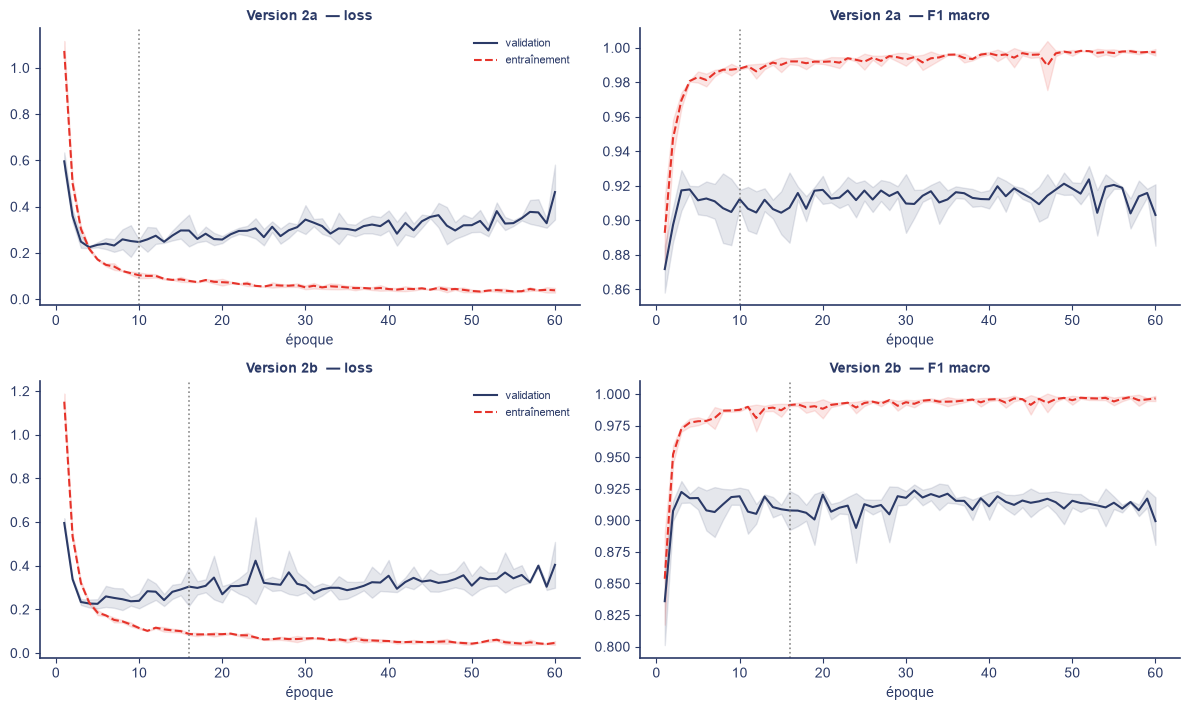

In [34]:
COURBES_EPOCHS = 60
courbes = {}
for cfg in CONFIGS:
    hs = [entrainer(cfg, X_tr, y_tr, COURBES_EPOCHS, seed=s, suivi=(X_va, y_va))[1] for s in range(3)]
    courbes[cfg["nom"]] = pd.concat(hs).groupby("epoch").agg(["mean", "std"])
    print(cfg["nom"], "terminé")

fig, ax = plt.subplots(len(CONFIGS), 2, figsize=(12, 3.6 * len(CONFIGS)), squeeze=False)
for i, cfg in enumerate(CONFIGS):
    h = courbes[cfg["nom"]]; ep = h.index
    for col, key, st, lab in [(BLEU, "val", "-", "validation"), (ROUGE, "train", "--", "entraînement")]:
        for j, m in enumerate(["loss", "f1"]):
            mu, sd = h[(f"{key}_{m}", "mean")], h[(f"{key}_{m}", "std")]
            ax[i, j].plot(ep, mu, st, color=col, label=lab)
            ax[i, j].fill_between(ep, mu - sd, mu + sd, color=col, alpha=0.12)
    for j, t in enumerate(["loss", "F1 macro"]):
        ax[i, j].axvline(cfg["epochs"], color=GRIS_LIGNE, linestyle=":", linewidth=1.2)
        ax[i, j].set_xlabel("époque"); ax[i, j].set_title(f"{cfg['nom'].split(':')[0]} — {t}", fontsize=10)
    ax[i, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Dans les deux versions, la loss d'entraînement tend vers 0 (≈ 0,04 à l'époque 60) et le F1 d'entraînement vers 1,00, alors que la loss de validation passe par un minimum (≈ 0,22 vers l'époque 4 à 6) puis remonte jusqu'à ≈ 0,35–0,45 : c'est du surapprentissage. 

Le F1 de validation, lui, n'a pas de véritable plateau stable : il atteint ≈ 0,92 dès les premières époques et reste entre 0,90 et 0,92, ce qui montre un excès de confiance du modèle plutôt qu'une vraie dégradation. La ligne verticale (époque 10 pour 2a, 16 pour 2b) tombe après le minimum de la loss, ce qui est cohérent avec le choix par F1. Les courbes de validation sont bruitées (pics à 0,43 en 2b, bande plus large), davantage pour la version profonde 2b. 

Il n'y a pas de sous-apprentissage : le modèle apprend en 3 à 4 époques.

## Évaluation finale sur le test

In [ ]:
CONFIRMER_TEST = True       
SEEDS_FINALES = [0, 1, 2, 3, 4]
FICHIER_TEST = "../results/test_final_v2.csv"

In [ ]:
def evaluation_finale():
    if os.path.exists(FICHIER_TEST):
            print(f"Note : {FICHIER_TEST} existe déjà, il est recalculé (graines fixées, résultats identiques).")
    test_df = pd.read_csv(f"{DATA_DIR}/test_processed.csv")            # première lecture du test
    X_test0 = test_df[feat].to_numpy(dtype=np.float32)
    y_test = test_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)

    sc = StandardScaler().fit(X_all)
    Xa = sc.transform(X_all).astype(np.float32)
    Xt = sc.transform(X_test0).astype(np.float32)
    test_loader = make_loader(Xt, y_test, 512)

    lignes, preds_seed0 = [], {}
    for cfg in CONFIGS:
        accs, f1s, parametres = [], [], None
        for s in SEEDS_FINALES:
            model, _ = entrainer(cfg, Xa, y_all, cfg["epochs"], seed=s)
            r = evaluate(model, test_loader)
            accs.append(r["acc"]); f1s.append(r["f1"])
            parametres = sum(p.numel() for p in model.parameters())
            if s == 0:
                preds_seed0[cfg["nom"]] = r["pred"]          # graine 0 fixée d'avance pour la matrice de confusion
        lignes.append({"configuration": cfg["nom"], "version": cfg["version"], "paramètres": parametres,
                       "époques": cfg["epochs"], "f1_cv": cfg["f1_cv"],
                       "test_acc": np.mean(accs), "test_acc_std": np.std(accs, ddof=1),
                       "test_f1": np.mean(f1s), "test_f1_std": np.std(f1s, ddof=1)})
        print(cfg["nom"], "évalué")

    lr = LogisticRegression(max_iter=500).fit(Xa, y_all)
    p_lr = lr.predict(Xt)
    lignes.append({"configuration": "Régression logistique", "version": 0, "paramètres": Xa.shape[1] * n_classes + n_classes,
                   "époques": np.nan, "f1_cv": np.nan, "test_acc": accuracy_score(y_test, p_lr), "test_acc_std": np.nan,
                   "test_f1": f1_score(y_test, p_lr, average="macro"), "test_f1_std": np.nan})
    preds_seed0["Régression logistique"] = p_lr
    res = pd.DataFrame(lignes)
    res.to_csv(FICHIER_TEST, index=False)
    return res, preds_seed0, y_test

if CONFIRMER_TEST:
    res_test, preds_seed0, y_test = evaluation_finale()
    afficher = res_test.copy()
    afficher["F1 test (± std graines)"] = [f"{m:.4f} ± {s:.4f}" if s == s else f"{m:.4f}" for m, s in zip(res_test["test_f1"], res_test["test_f1_std"])]
    afficher["accuracy test"] = [f"{m:.4f} ± {s:.4f}" if s == s else f"{m:.4f}" for m, s in zip(res_test["test_acc"], res_test["test_acc_std"])]
    afficher["F1 validation croisée"] = afficher["f1_cv"].round(4)
    afficher["test - validation"] = (res_test["test_f1"] - res_test["f1_cv"]).round(4)
    display(afficher[["configuration", "paramètres", "époques", "F1 validation croisée", "F1 test (± std graines)",
                      "accuracy test", "test - validation"]])
else:
    print("Test non évalué : CONFIRMER_TEST = TRUE.")

Note : ../results/test_final_v2.csv existe déjà, il est recalculé (graines fixées, résultats identiques).
Version 2a : 2 couches (128,64), BatchNorm + dropout 0,5 évalué
Version 2b : 3 couches (256,128,64), BatchNorm + dropout 0,5 + weight decay 1e-4 évalué


,configuration,paramètres,époques,F1 validation croisée,F1 test (± std graines),accuracy test,test - validation
0,"Version 2a : 2 couches (128,64), BatchNorm + d...",80966,10.0,0.9312,0.9403 ± 0.0089,0.9397 ± 0.0089,0.0091
1,"Version 2b : 3 couches (256,128,64), BatchNorm...",186310,16.0,0.9306,0.9512 ± 0.0075,0.9510 ± 0.0074,0.0206
2,Régression logistique,3372,NaN,NaN,0.9555,0.9555,NaN


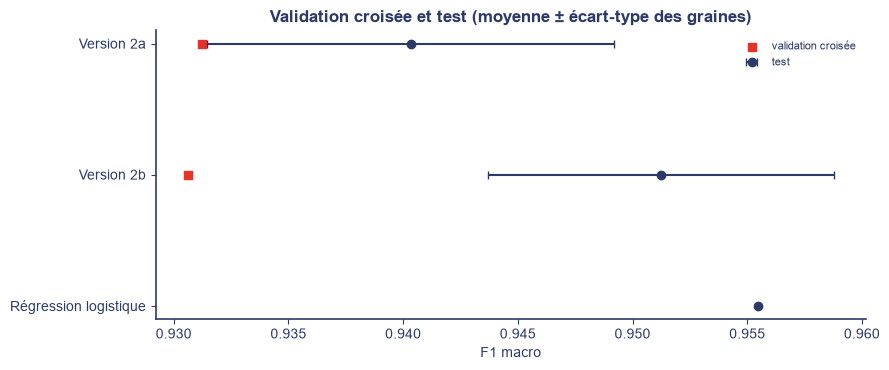

In [37]:
if CONFIRMER_TEST:
    fig, ax = plt.subplots(figsize=(9, 3.8))
    noms = [n.split(":")[0].strip() if ":" in n else n for n in res_test["configuration"]]
    y = np.arange(len(res_test))[::-1]
    ax.errorbar(res_test["test_f1"], y, xerr=res_test["test_f1_std"].fillna(0), fmt="o", color=BLEU, capsize=3, label="test")
    ax.scatter(res_test["f1_cv"], y, marker="s", color=ROUGE, label="validation croisée")
    ax.set_yticks(y); ax.set_yticklabels(noms); ax.set_xlabel("F1 macro")
    ax.set_title("Validation croisée et test (moyenne ± écart-type des graines)")
    ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

### Matrices de confusion et rapport par classe

Pour chaque version, on affiche le modèle de graine 0 (graine choisie d'avance, pas la meilleure sur le test).

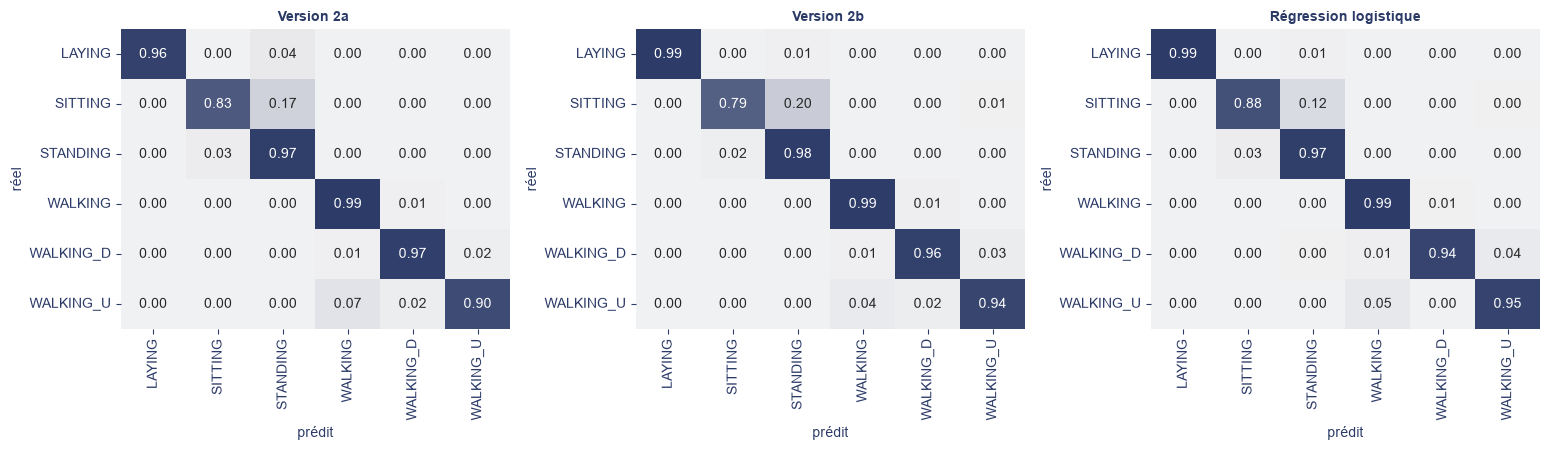


Version 2a : 2 couches (128,64), BatchNorm + dropout 0,5
                    precision    recall  f1-score   support

            LAYING      1.000     0.957     0.978       537
           SITTING      0.967     0.827     0.891       491
          STANDING      0.827     0.974     0.895       532
           WALKING      0.927     0.992     0.958       496
WALKING_DOWNSTAIRS      0.967     0.971     0.969       420
  WALKING_UPSTAIRS      0.979     0.902     0.939       471

          accuracy                          0.938      2947
         macro avg      0.944     0.937     0.938      2947
      weighted avg      0.943     0.938     0.938      2947


Version 2b : 3 couches (256,128,64), BatchNorm + dropout 0,5 + weight decay 1e-4
                    precision    recall  f1-score   support

            LAYING      1.000     0.991     0.995       537
           SITTING      0.977     0.794     0.876       491
          STANDING      0.834     0.983     0.903       532
           WALKI

In [38]:
if CONFIRMER_TEST:
    a_montrer = [c["nom"] for c in CONFIGS] + ["Régression logistique"]
    fig, ax = plt.subplots(1, len(a_montrer), figsize=(5.2 * len(a_montrer), 4.6))
    for a, nom in zip(np.atleast_1d(ax), a_montrer):
        cm = confusion_matrix(y_test, preds_seed0[nom], normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap_bleu, cbar=False, ax=a, vmin=0, vmax=1,
                    xticklabels=[c[:9] for c in classes], yticklabels=[c[:9] for c in classes])
        a.set_title(nom.split(":")[0] if ":" in nom else nom, fontsize=10)
        a.set_xlabel("prédit"); a.set_ylabel("réel")
    plt.tight_layout(); plt.show()
    for nom in a_montrer:
        print("\n" + nom)
        print(classification_report(y_test, preds_seed0[nom], target_names=classes, digits=3))

NB:(2a = 2 couches (128,64) avec BatchNorm + dropout ; 2b = 3 couches (256,128,64) avec BatchNorm + dropout + weight decay.)

- **Test vs validation croisée** : 2a = 0,9403 ± 0,0089 (+0,009) et 2b = 0,9512 ± 0,0075 (+0,021), contre ≈ 0,931 en validation croisée. Le test est plus favorable, car la validation croisée est pénalisée par les partitions difficiles (écart-type ≈ 0,05).
- **2a vs 2b** : 2b est meilleure de 0,011, ce qui dépasse à peine l'écart-type entre graines : différence modeste.
- **Régression logistique** : 0,9555, donc meilleure que les deux MLP ; 2b s'en rapproche (−0,004).
- **Erreurs** : SITTING est confondu avec STANDING (rappel 0,83 en 2a, 0,79 en 2b, contre 0,88 pour la régression logistique). WALKING_UPSTAIRS est aussi pris pour WALKING (7 % en 2a).


# Interprétabilité et réduction de dimension

**Objectif.** Je veux voir comment le réseau « voit » les classes : je projette en 2D (t-SNE et UMAP) les **activations de la dernière couche cachée** et, pour comparer, les **variables d'entrée brutes** (561 features), puis je compare avec la **matrice de confusion**.

**Règle de données.** J'ai déjà utilisé le jeu de test en partie 5, donc ici je n'utilise que les données d'apprentissage : j'entraîne les modèles sur les 16 volontaires du découpage de la partie 2 et je fais les projections sur les **5 volontaires de validation**, que les modèles n'ont pas vus. Ainsi, je ne touche pas au test pour cette analyse qualitative.

**Modèles.** Je reprends les deux versions de la partie 5 : la version 1 (1×64) et la version 2b (3×(256,128,64), BatchNorm + dropout + weight decay), avec le nombre d'époques fixé par la validation croisée.

##  principe et limites de t-SNE et UMAP


**t-SNE.** Pour chaque point, je calcule la probabilité que les autres soient ses voisins (loi gaussienne dans l'espace d'origine, réglée par la **perplexité**, nombre effectif de voisins considérés). Je cherche ensuite des positions 2D dont les probabilités de voisinage (loi de Student, à queues lourdes) ressemblent à celles de l'espace d'origine, en minimisant une divergence de Kullback-Leibler.
- Limites : les **distances entre groupes** et les **tailles des groupes** ne sont pas interprétables ; le résultat dépend de la perplexité et de l'initialisation ; la méthode est coûteuse sur de gros jeux de données ; elle ne permet pas de projeter directement de nouveaux points.

**UMAP.** Je construis un graphe de voisinage pondéré dans l'espace d'origine (selon `n_neighbors`), puis j'optimise une disposition 2D qui conserve cette structure de graphe. UMAP est en général plus rapide que t-SNE et conserve mieux la structure globale, mais sans garantie.
- Limites : très sensible à `n_neighbors` et `min_dist` ; les distances entre groupes restent peu fiables ; des groupes peuvent apparaître ou se séparer artificiellement.

**Conséquence pour l'interprétation.** Je considère ces projections comme **qualitatives**. Un chevauchement visible suggère une confusion possible, mais un bon recouvrement entre deux classes n'est pas une preuve. C'est pourquoi j'ajoute une mesure quantitative (score de silhouette dans l'espace d'origine) et la comparaison avec la matrice de confusion.

In [51]:
import os, json, random, warnings

from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, silhouette_score

try:
    import umap
    UMAP_OK = True
except ImportError:
    UMAP_OK = False
    print("umap-learn n'est pas installé : pip install umap-learn  (les figures UMAP seront ignorées)")

warnings.filterwarnings("ignore")

set_seed(0)


In [52]:
all_df = pd.concat([pd.read_csv(f"{DATA_DIR}/train_processed.csv"),
                    pd.read_csv(f"{DATA_DIR}/val_processed.csv")], ignore_index=True)   # le test n'est pas chargé
feat = [c for c in all_df.columns if c not in ("subject", "Activity")]
classes = sorted(all_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_all = all_df[feat].to_numpy(dtype=np.float32)
y_all = all_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
subj  = all_df["subject"].to_numpy()
in_dim = X_all.shape[1]

val_subjects = json.load(open("../data/split_volontaires.json"))["val_subjects"]
est_val = np.isin(subj, val_subjects)
X_tr, y_tr = X_all[~est_val], y_all[~est_val]
X_va, y_va, s_va = X_all[est_val], y_all[est_val], subj[est_val]
print("entraînement :", X_tr.shape, "| validation :", X_va.shape, "| volontaires de validation :", val_subjects)

CONFIGS = [
    {"nom": "Version 1 (1x64)", "hidden": (64,), "dropout": 0.0, "norm": None, "wd": 0.0,
     "nom_cv": "1x64 : référence"},
    {"nom": "Version 2b (3x(256,128,64), BN + dropout + wd)", "hidden": (256, 128, 64), "dropout": 0.5, "norm": "bn", "wd": 1e-4,
     "nom_cv": "3x(256,128,64) : BatchNorm + dropout + weight decay"},
]
cv = pd.read_csv("../results/partie4b_retenues_3graines.csv")
for cfg in CONFIGS:
    es = cv[cv["configuration"] == cfg["nom_cv"] + " + arrêt précoce"]
    if es.empty:
        raise ValueError(f"Configuration absente du CSV de la partie 4 : {cfg['nom_cv']!r}")
    cfg["epochs"] = max(5, int(round(es["best_epoch"].median())))
    print(cfg["nom"], "-> époques :", cfg["epochs"])


entraînement : (5657, 561) | validation : (1695, 561) | volontaires de validation : [8, 11, 16, 19, 23]
Version 1 (1x64) -> époques : 10
Version 2b (3x(256,128,64), BN + dropout + wd) -> époques : 16


In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden=(64,), n_classes=6, dropout=0.0, norm=None):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if norm == "bn":
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        self.features = nn.Sequential(*layers)      
        self.out_layer = nn.Linear(d, n_classes)

    def forward(self, x):
        return self.out_layer(self.features(x))

def entrainer(cfg, X, y, seed=0):
    set_seed(seed)
    model = MLP(in_dim, cfg["hidden"], n_classes, cfg["dropout"], cfg["norm"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=cfg["wd"])
    crit = nn.CrossEntropyLoss()
    loader = make_loader(X, y, 128, shuffle=True, seed=seed)
    for _ in range(cfg["epochs"]):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
    return model.eval()

@torch.no_grad()
def predire_et_projeter(model, X):
    xb = torch.from_numpy(X).to(device)
    return model(xb).argmax(1).cpu().numpy(), model.features(xb).cpu().numpy()

modeles, pred, latent = {}, {}, {}
for cfg in CONFIGS:
    modeles[cfg["nom"]] = entrainer(cfg, X_tr, y_tr, seed=0)
    pred[cfg["nom"]], latent[cfg["nom"]] = predire_et_projeter(modeles[cfg["nom"]], X_va)
    print(f"{cfg['nom']} | F1 validation = {f1_score(y_va, pred[cfg['nom']], average='macro'):.4f} "
          f"| espace latent : {latent[cfg['nom']].shape}")

Version 1 (1x64) | F1 validation = 0.9210 | espace latent : (1695, 64)
Version 2b (3x(256,128,64), BN + dropout + wd) | F1 validation = 0.9192 | espace latent : (1695, 64)


##  à quel point les classes sont-elles séparées ?

Le **score de silhouette** (calculé dans l'espace d'origine, avant projection 2D) mesure si chaque point est plus proche de sa classe que des autres : proche de 1 = classes bien séparées, proche de 0 = classes qui se chevauchent. On le calcule pour toutes les classes et pour la paire SITTING / STANDING seule.

In [42]:
idx_sit, idx_stand = class_to_idx["SITTING"], class_to_idx["STANDING"]
paire = np.isin(y_va, [idx_sit, idx_stand])

espaces = {"Variables brutes (561)": X_va, **{f"Latent : {n}": latent[n] for n in latent}}
lignes = []
for nom, Z in espaces.items():
    lignes.append({"espace": nom, "dimension": Z.shape[1],
                   "silhouette (6 classes)": silhouette_score(Z, y_va),
                   "silhouette SITTING vs STANDING": silhouette_score(Z[paire], y_va[paire])})
display(pd.DataFrame(lignes).round(3))

,espace,dimension,silhouette (6 classes),silhouette SITTING vs STANDING
0,Variables brutes (561),561,0.025,0.031
1,Latent : Version 1 (1x64),64,0.299,0.304
2,"Latent : Version 2b (3x(256,128,64), BN + drop...",64,0.562,0.493


##  t-SNE

t-SNE Variables brutes (561) terminé
t-SNE Latent : Version 1 (1x64) terminé
t-SNE Latent : Version 2b (3x(256,128,64), BN + dropout + wd) terminé


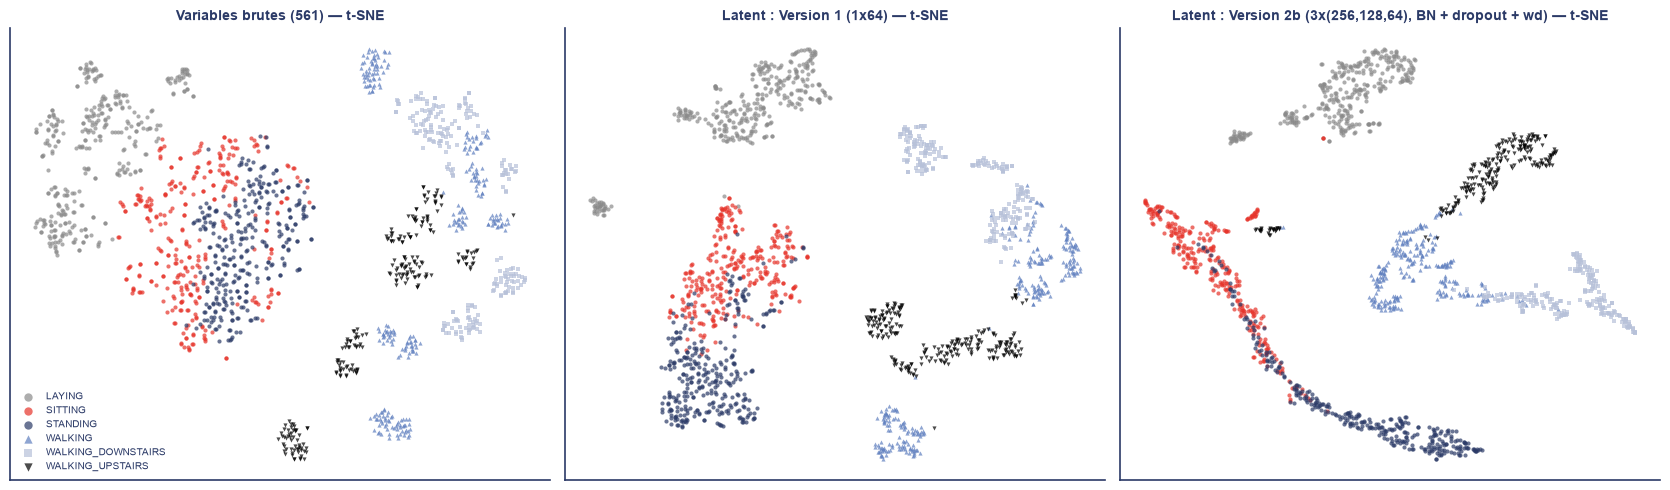

In [ ]:
ORDRE = ["LAYING", "SITTING", "STANDING", "WALKING", "WALKING_DOWNSTAIRS", "WALKING_UPSTAIRS"]
STYLE = {"LAYING": (GRIS_LIGNE, "o"), "SITTING": (ROUGE, "o"), "STANDING": (BLEU, "o"),
         "WALKING": ("#5F7FBF", "^"), "WALKING_DOWNSTAIRS": ("#B7C1D9", "s"), "WALKING_UPSTAIRS": ("#000000", "v")}

def nuage(ax, E, titre, labels=y_va):
    for c in ORDRE:
        m = labels == class_to_idx[c]
        col, mk = STYLE[c]
        ax.scatter(E[m, 0], E[m, 1], s=9, c=col, marker=mk, alpha=0.7, linewidths=0, label=c)
    ax.set_title(titre, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

def projeter(methode):
    emb = {}
    for nom, Z in espaces.items():
        if methode == "t-SNE":
            emb[nom] = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(Z)
        else:
            emb[nom] = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit_transform(Z)
        print(methode, nom, "terminé")
    return emb

def figure(emb, methode):
    fig, ax = plt.subplots(1, len(emb), figsize=(5.6 * len(emb), 5))
    for a, (nom, E) in zip(ax, emb.items()):
        nuage(a, E, f"{nom} — {methode}")
    ax[0].legend(frameon=False, fontsize=7, markerscale=2, loc="best")
    plt.tight_layout(); plt.show()

emb_tsne = projeter("t-SNE")
figure(emb_tsne, "t-SNE")

##  UMAP

(`n_neighbors` = 30, `min_dist` = 0,3.)

UMAP Variables brutes (561) terminé
UMAP Latent : Version 1 (1x64) terminé
UMAP Latent : Version 2b (3x(256,128,64), BN + dropout + wd) terminé


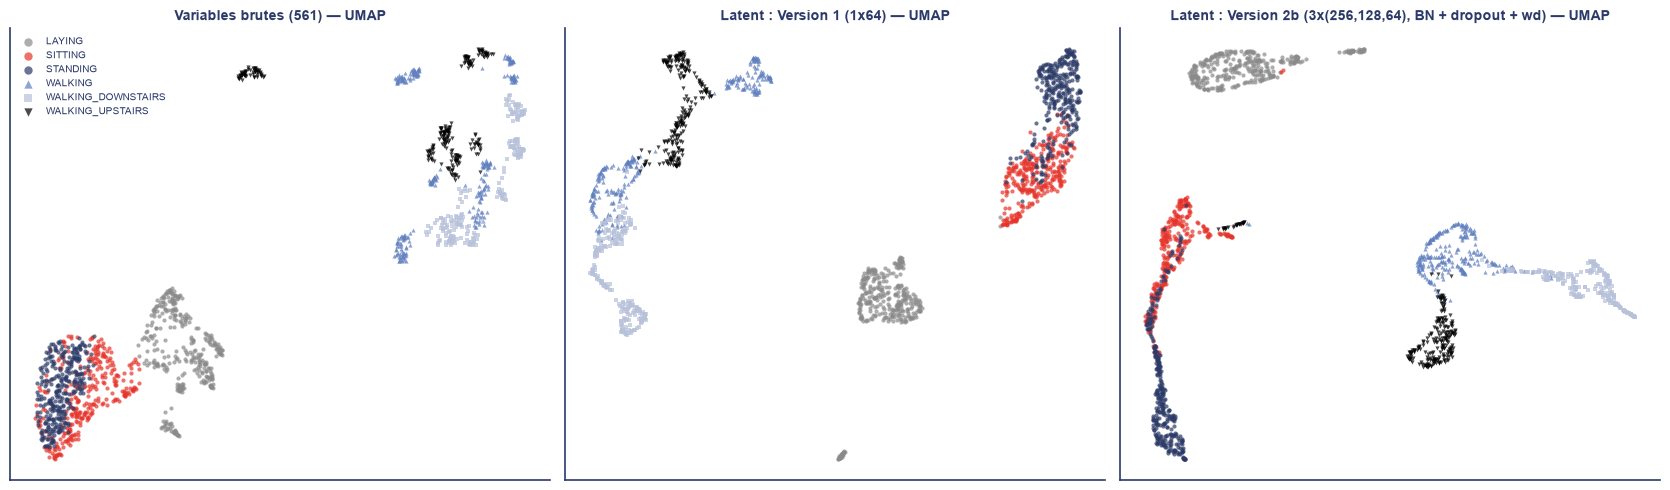

In [44]:
if UMAP_OK:
    emb_umap = projeter("UMAP")
    figure(emb_umap, "UMAP")

##  la matrice de confusion



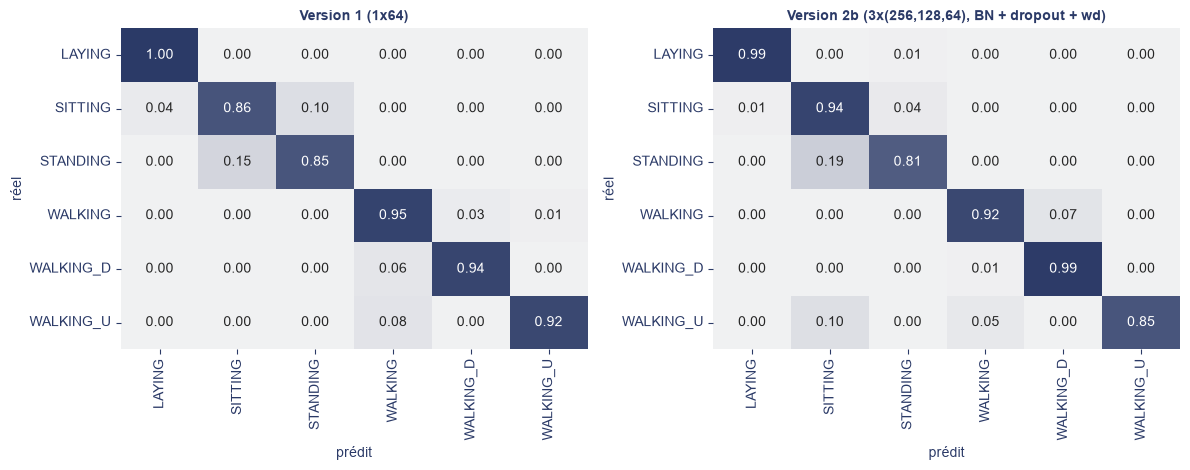

Les 5 confusions les plus fréquentes (modèle Version 2b (3x(256,128,64), BN + dropout + wd)) :
  STANDING             -> SITTING              19.06%
  WALKING_UPSTAIRS     -> SITTING              10.13%
  WALKING              -> WALKING_DOWNSTAIRS   7.06%
  WALKING_UPSTAIRS     -> WALKING              5.06%
  SITTING              -> STANDING             4.21%


In [ ]:
fig, ax = plt.subplots(1, len(modeles), figsize=(6 * len(modeles), 4.8))
for a, nom in zip(np.atleast_1d(ax), modeles):
    cm = confusion_matrix(y_va, pred[nom], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap_bleu, cbar=False, ax=a, vmin=0, vmax=1,
                xticklabels=[c[:9] for c in classes], yticklabels=[c[:9] for c in classes])
    a.set_title(nom, fontsize=10); a.set_xlabel("prédit"); a.set_ylabel("réel")
plt.tight_layout(); plt.show()

nom_b = CONFIGS[-1]["nom"]
cm = confusion_matrix(y_va, pred[nom_b], normalize="true"); np.fill_diagonal(cm, 0)
paires = sorted([(cm[i, j], classes[i], classes[j]) for i in range(n_classes) for j in range(n_classes) if i != j], reverse=True)[:5]
print("Les 5 confusions les plus fréquentes (modèle", nom_b + ") :")
for v, a, b in paires:
    print(f"  {a:20s} -> {b:20s} {v:.2%}")

On recolore les mêmes projections t-SNE par **volontaire**. Si les points d'un même volontaire forment des groupes distincts, une partie de la structure vient du volontaire : c'est le décalage entre volontaires qui limite la généralisation .

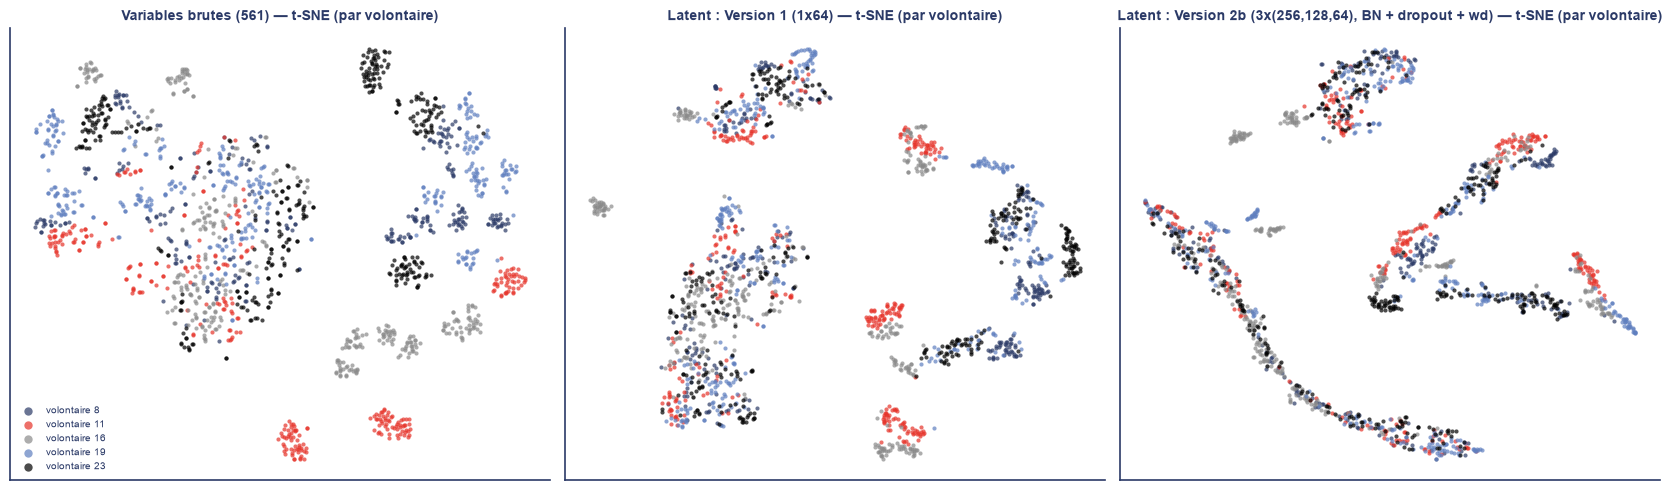

In [46]:
COUL_VOL = [BLEU, ROUGE, GRIS_LIGNE, "#5F7FBF", "#000000"]
fig, ax = plt.subplots(1, len(emb_tsne), figsize=(5.6 * len(emb_tsne), 5))
for a, (nom, E) in zip(ax, emb_tsne.items()):
    for v, col in zip(val_subjects, COUL_VOL):
        m = s_va == v
        a.scatter(E[m, 0], E[m, 1], s=9, c=col, alpha=0.7, linewidths=0, label=f"volontaire {v}")
    a.set_title(f"{nom} — t-SNE (par volontaire)", fontsize=10); a.set_xticks([]); a.set_yticks([])
ax[0].legend(frameon=False, fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

## Projections sur le jeu de test 


In [ ]:
test_df = pd.read_csv(f"{DATA_DIR}/test_processed.csv")
X_test0 = test_df[feat].to_numpy(dtype=np.float32)
y_test = test_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
s_test = test_df["subject"].to_numpy() if "subject" in test_df.columns else None

sc = StandardScaler().fit(X_all)                     
Xa = sc.transform(X_all).astype(np.float32)
Xt = sc.transform(X_test0).astype(np.float32)

modeles_t, pred_t, latent_t = {}, {}, {}
for cfg in CONFIGS:
    modeles_t[cfg["nom"]] = entrainer(cfg, Xa, y_all, seed=0)
    pred_t[cfg["nom"]], latent_t[cfg["nom"]] = predire_et_projeter(modeles_t[cfg["nom"]], Xt)
    print(f"{cfg['nom']} | F1 test (graine 0) = {f1_score(y_test, pred_t[cfg['nom']], average='macro'):.4f}")

espaces_t = {"Variables brutes (561)": Xt, **{f"Latent : {n}": latent_t[n] for n in latent_t}}
paire_t = np.isin(y_test, [class_to_idx["SITTING"], class_to_idx["STANDING"]])
lignes = [{"espace": nom, "dimension": Z.shape[1],
           "silhouette (6 classes)": silhouette_score(Z, y_test),
           "silhouette SITTING vs STANDING": silhouette_score(Z[paire_t], y_test[paire_t])}
          for nom, Z in espaces_t.items()]
display(pd.DataFrame(lignes).round(3))


Version 1 (1x64) | F1 test (graine 0) = 0.9451
Version 2b (3x(256,128,64), BN + dropout + wd) | F1 test (graine 0) = 0.9431


,espace,dimension,silhouette (6 classes),silhouette SITTING vs STANDING
0,Variables brutes (561),561,0.041,0.030
1,Latent : Version 1 (1x64),64,0.381,0.327
2,"Latent : Version 2b (3x(256,128,64), BN + drop...",64,0.653,0.565


t-SNE Variables brutes (561) terminé
t-SNE Latent : Version 1 (1x64) terminé
t-SNE Latent : Version 2b (3x(256,128,64), BN + dropout + wd) terminé


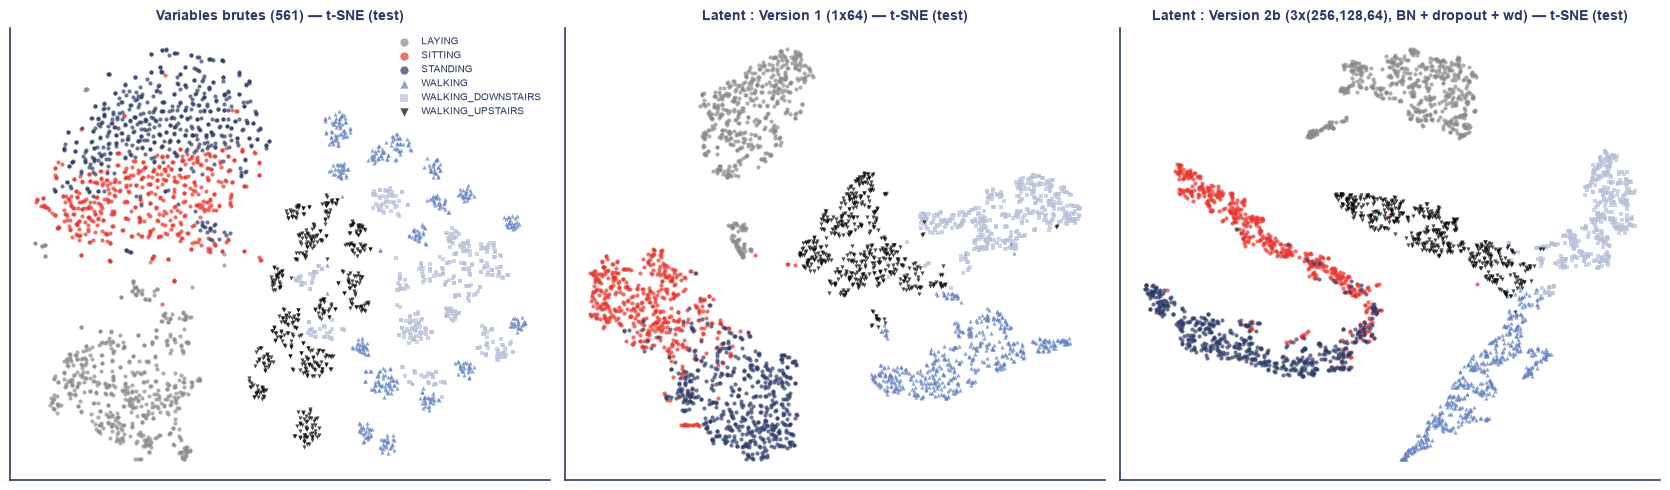

UMAP Variables brutes (561) terminé
UMAP Latent : Version 1 (1x64) terminé
UMAP Latent : Version 2b (3x(256,128,64), BN + dropout + wd) terminé


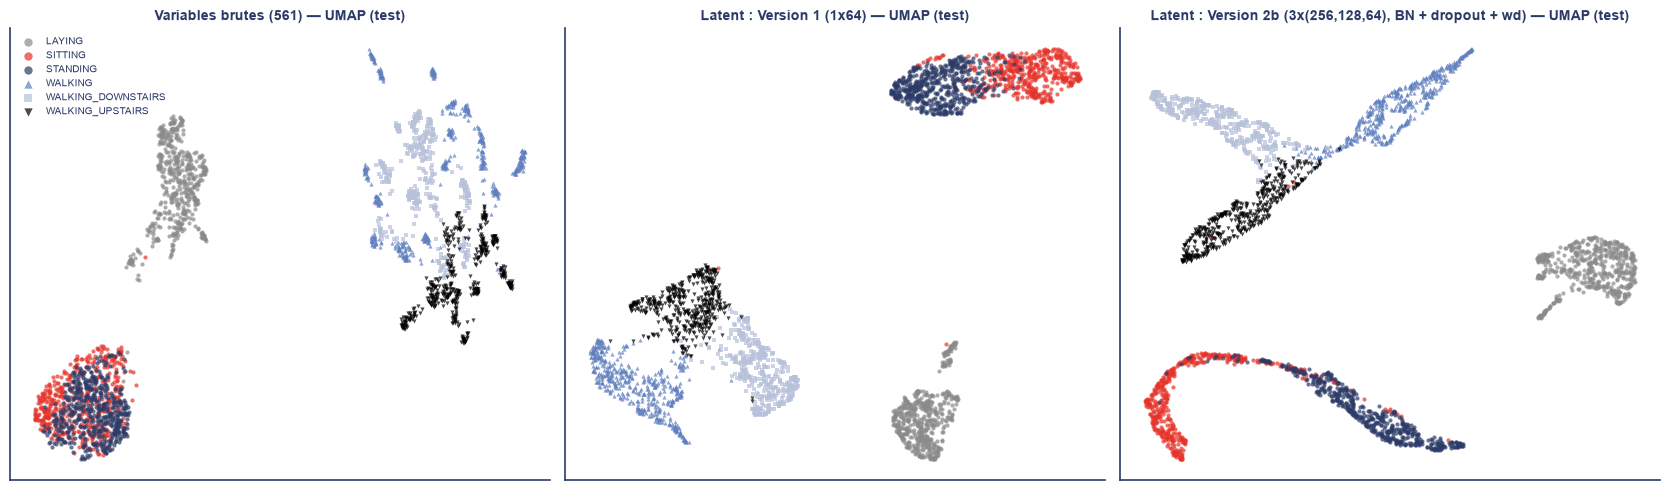

In [48]:
def projeter_test(methode):
    emb = {}
    for nom, Z in espaces_t.items():
        if methode == "t-SNE":
            emb[nom] = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(Z)
        else:
            emb[nom] = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit_transform(Z)
        print(methode, nom, "terminé")
    return emb

def figure_test(emb, methode):
    fig, ax = plt.subplots(1, len(emb), figsize=(5.6 * len(emb), 5))
    for a, (nom, E) in zip(ax, emb.items()):
        nuage(a, E, f"{nom} — {methode} (test)", labels=y_test)
    ax[0].legend(frameon=False, fontsize=7, markerscale=2, loc="best")
    plt.tight_layout(); plt.show()

emb_tsne_t = projeter_test("t-SNE")
figure_test(emb_tsne_t, "t-SNE")
if UMAP_OK:
    emb_umap_t = projeter_test("UMAP")
    figure_test(emb_umap_t, "UMAP")

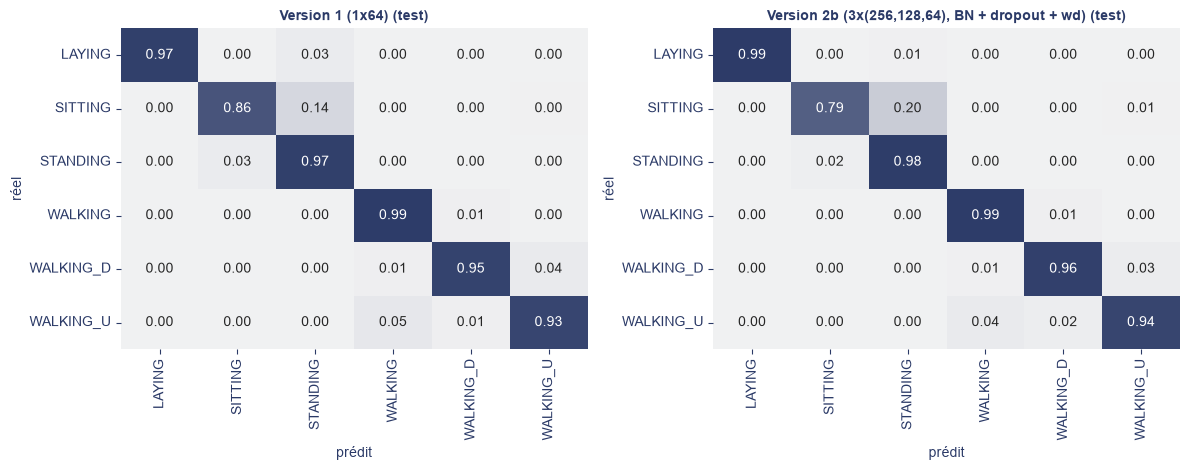

Version 1 (1x64) : confusions les plus fréquentes
   SITTING              -> STANDING             13.85%
   WALKING_UPSTAIRS     -> WALKING              5.31%
   WALKING_DOWNSTAIRS   -> WALKING_UPSTAIRS     3.57%
   STANDING             -> SITTING              3.20%
Version 2b (3x(256,128,64), BN + dropout + wd) : confusions les plus fréquentes
   SITTING              -> STANDING             19.96%
   WALKING_UPSTAIRS     -> WALKING              3.61%
   WALKING_DOWNSTAIRS   -> WALKING_UPSTAIRS     2.86%
   WALKING_UPSTAIRS     -> WALKING_DOWNSTAIRS   2.34%


In [49]:
fig, ax = plt.subplots(1, len(modeles_t), figsize=(6 * len(modeles_t), 4.8))
for a, nom in zip(np.atleast_1d(ax), modeles_t):
    cm = confusion_matrix(y_test, pred_t[nom], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap_bleu, cbar=False, ax=a, vmin=0, vmax=1,
                xticklabels=[c[:9] for c in classes], yticklabels=[c[:9] for c in classes])
    a.set_title(nom + " (test)", fontsize=10); a.set_xlabel("prédit"); a.set_ylabel("réel")
plt.tight_layout(); plt.show()

for nom in modeles_t:
    cm = confusion_matrix(y_test, pred_t[nom], normalize="true"); np.fill_diagonal(cm, 0)
    top = sorted([(cm[i, j], classes[i], classes[j]) for i in range(n_classes) for j in range(n_classes) if i != j], reverse=True)[:4]
    print(nom, ": confusions les plus fréquentes")
    for v, a_, b_ in top:
        print(f"   {a_:20s} -> {b_:20s} {v:.2%}")

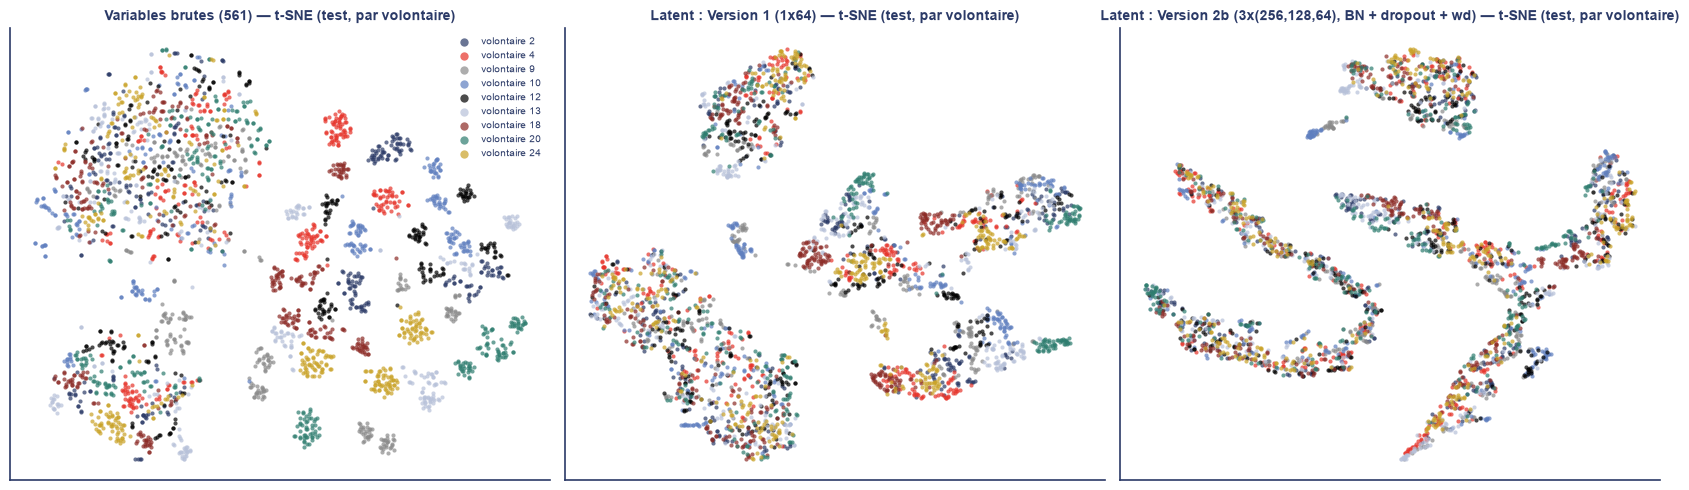

In [50]:
if s_test is not None:
    vols = sorted(np.unique(s_test))
    palette = [BLEU, ROUGE, GRIS_LIGNE, "#5F7FBF", "#000000", "#B7C1D9", "#8C2B26", "#2E7D6F", "#C9A227"]
    fig, ax = plt.subplots(1, len(emb_tsne_t), figsize=(5.6 * len(emb_tsne_t), 5))
    for a, (nom, E) in zip(ax, emb_tsne_t.items()):
        for v, col in zip(vols, palette):
            m = s_test == v
            a.scatter(E[m, 0], E[m, 1], s=9, c=col, alpha=0.7, linewidths=0, label=f"volontaire {v}")
        a.set_title(f"{nom} — t-SNE (test, par volontaire)", fontsize=10); a.set_xticks([]); a.set_yticks([])
    ax[0].legend(frameon=False, fontsize=7, markerscale=2)
    plt.tight_layout(); plt.show()
else:
    print("La colonne 'subject' est absente du fichier de test : projection par volontaire ignorée.")

**Ce que montrent les projections.**

- **Variables brutes** : LAYING et les trois marches sont déjà bien séparées, mais SITTING et STANDING se mélangent presque complètement. La silhouette est proche de 0, ce qui confirme ce que l'on voit.
- **Espace latent** : les classes sont plus compactes et plus éloignées les unes des autres. La silhouette passe de ≈ 0 (brutes) à une valeur moyenne pour la version 1, puis à une valeur élevée pour la version 2b.
- **Version 2b** : c'est elle qui sépare le mieux, y compris SITTING et STANDING, qui forment deux groupes distincts le long d'une même courbe. 

**Comparaison avec la matrice de confusion.**

- **Accord** : les classes qui se chevauchent dans t-SNE/UMAP (SITTING et STANDING) sont celles que la matrice de confusion mélange le plus. Le réseau les rapproche moins qu'avec les variables brutes, mais ne supprime pas la difficulté.
- **Réseau** : il regroupe mieux les classes, mais une meilleure silhouette ne garantit pas moins d'erreurs : la version 2b est la mieux séparée, et confond pourtant autant STANDING avec SITTING.
- **Volontaires** : très marqués dans les variables brutes, atténués dans l'espace latent sans disparaître.
- **Limites** : projections qualitatives, dépendantes des paramètres, distances non interprétables.

## Bilan de cette partie 

- Les projections montrent que la difficulté du problème se limite à SITTING/STANDING : les autres classes sont séparables dès les variables brutes.
- Le réseau réorganise l'espace : il rend les classes plus compactes, surtout avec la version 2b (plus profonde et régularisée). Cette meilleure séparation ne se traduit pas par moins de confusions SITTING/STANDING.
- L'effet du volontaire est fort dans les données brutes, et il est atténué dans l'espace latent. Cela confirme que la généralisation à de nouveaux volontaires est le vrai défi.
- Limites : analyse qualitative, dépendante des paramètres, et les distances ne sont pas fiables. Je m'en sers pour illustrer et comparer avec la matrice de confusion, pas pour prouver.
